# Scrap notebooks

This notebook is just a compilation of scrapy tests to view functions

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy.stats as stats
import scipy.optimize as opt
import scipy.integrate as integr
import scipy.interpolate as interp

from tqdm import tqdm
import itertools

import pandas as pd

In [2]:
#%matplotlib widget

### Plotting solutions

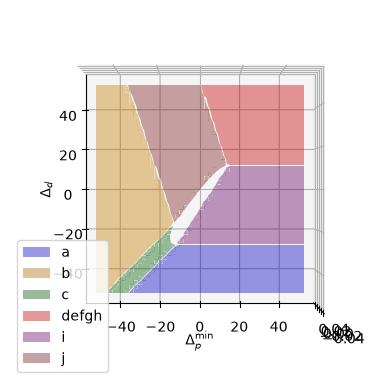

In [3]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.set_xlabel(r'$\Delta_d$')
ax.set_ylabel(r'$\Delta_p^{\text{min}}$')

N_value = 10000
s_value = 2000
M_value = 3

Delta_p_max_minus_min_value = 15
alpha_value = 2
beta_value = 1
gamma_value = 4
delta_value = beta_value * gamma_value / (beta_value + gamma_value)
phi_value = 0.3
f_value = 1
E_value = 1

eps = 0.5
dim = 200
alpha = 0.4

Delta_d_values = np.linspace(-50, 50, dim)
Delta_p_min_values = np.linspace(-50, 50, dim)
Delta_d_values, Delta_p_min_values = np.meshgrid(Delta_d_values, Delta_p_min_values)
#F_func = stats.uniform(scale = Delta_p_max_minus_min_value, loc = Delta_p_min_values)
F_func = stats.triang(c = 0.7, scale = Delta_p_max_minus_min_value, loc = Delta_p_min_values)
Delta_p_full_values = F_func.ppf(M_value / (M_value + 1))

zone = np.zeros((dim, dim))


SC_a_values = zone.copy()
SC_a_values[-2 * delta_value * N_value / (phi_value * s_value) - Delta_d_values <=0] = np.nan
SC_a_values[Delta_p_min_values - E_value - f_value - Delta_d_values - delta_value * N_value / (phi_value * s_value) <= 0] = np.nan
ax.plot_surface(Delta_d_values, Delta_p_min_values, SC_a_values, label="a", alpha=alpha, color="blue")


SC_b_values = zone.copy()
SC_b_values[M_value * (f_value + E_value - Delta_p_full_values) - Delta_d_values - 2 * delta_value * N_value / (phi_value * s_value) <= 0] = np.nan
SC_b_values[E_value + f_value + Delta_d_values + delta_value * N_value / (phi_value * s_value) - Delta_p_full_values <= 0] = np.nan
ax.plot_surface(Delta_d_values, Delta_p_min_values, SC_b_values, label="b", alpha=alpha, color="orange")

SC_c_values = zone.copy()
SC_c_values[delta_value * N_value / (phi_value * s_value) + Delta_d_values + f_value + E_value < Delta_p_min_values] = np.nan
SC_c_values[delta_value * N_value / (phi_value * s_value) + Delta_d_values + f_value + E_value > Delta_p_full_values] = np.nan
SC_c_values[Delta_d_values + delta_value * N_value / (phi_value * s_value) * (2 - F_func.cdf(delta_value * N_value / (phi_value * s_value) + Delta_d_values + f_value + E_value)) >= 0] = np.nan
ax.plot_surface(Delta_d_values, Delta_p_min_values, SC_c_values, label="c", alpha=alpha, color="green")

SC_defgh_values = zone.copy()
SC_defgh_values[M_value * (Delta_p_min_values - f_value - E_value) + Delta_d_values - (M_value + 1) * 2 * delta_value * N_value / ((1 - phi_value) * s_value) <= 0] = np.nan
SC_defgh_values[Delta_d_values - 2 * delta_value * N_value / ((1 - phi_value) * s_value) <= 0] = np.nan

ax.plot_surface(Delta_d_values, Delta_p_min_values, SC_defgh_values, label="defgh", alpha=alpha, color="red")


SC_i_values = zone.copy()
SC_i_values[-2 * delta_value * N_value /(s_value * phi_value) > Delta_d_values] = np.nan
SC_i_values[2 * delta_value * N_value /(s_value * (1 - phi_value)) < Delta_d_values] = np.nan
SC_i_values[2 * (Delta_p_min_values - E_value - f_value) - Delta_d_values * (1 + phi_value) - 2 * delta_value * N_value / s_value <= 0] = np.nan
ax.plot_surface(Delta_d_values, Delta_p_min_values, SC_i_values, label="i", alpha=alpha, color="purple")


SC_j_values = zone.copy()
SC_j_values[-Delta_d_values + M_value * (f_value + E_value) < M_value * Delta_p_min_values - 2 * delta_value * N_value * (M_value + 1) / ((1 - phi_value) * s_value)] = np.nan
SC_j_values[-Delta_d_values + M_value * (f_value + E_value) > M_value * Delta_p_full_values + 2 * delta_value * N_value / (phi_value * s_value)] = np.nan

N_d_j_lim = np.maximum(0,
                       phi_value * (1 - phi_value) * (2 * N_value / (1 - phi_value) - Delta_d_values * s_value / delta_value) / (M_value + 2 + M_value * phi_value)
                      )

#N_d_j_lim[N_d_j_lim < 0] = np.nan
#N_d_j_lim[N_d_j_lim > N_value / (M_value + 1)] = np.nan

SC_j_values[2 * delta_value * (M_value + 1) / s_value *(-N_value/(1 - phi_value) + (1 + M_value * phi_value) / (phi_value * (1 - phi_value)) * N_d_j_lim)\
            + Delta_d_values\
            + M_value*(F_func.ppf(M_value * N_d_j_lim / N_value) - f_value - E_value)\
            > 0] = np.nan

SC_j_values[np.isnan(2 * delta_value * (M_value + 1) / s_value *(-N_value/(1 - phi_value) + (1 + M_value * phi_value) / (phi_value * (1 - phi_value)) * N_d_j_lim)\
            + Delta_d_values\
            + M_value*(F_func.ppf(M_value * N_d_j_lim / N_value) - f_value - E_value))\
           ] = np.nan



ax.plot_surface(Delta_d_values, Delta_p_min_values, SC_j_values, label="j", alpha=alpha, color="brown")

# case k is to hard to plot (solution should be solved for every point)


ax.view_init(-90, 0, 0)
ax.legend()

In [6]:
color_legend = {"D": "blue",
                "DPmax": "orange",
                "DP": "green",
                "S": "red",
                "SD": "purple",
                "SDPmax": "brown",
                "SDP": "black",
                "SDPmax_phi_interior": "brown",
                "SDPmax_phi_left": "pink",
                "SDPmax_phi_right": "yellow",
                "SDP_phi_left": "gray",
                "SDP_phi_right": "gray",
                "SDP_phi_interior": "black"
               }

case_to_color_transform = np.vectorize(lambda x: color_legend[x])

In [7]:
def recursive_root_finder(f, start_min, start_max, depth, eps = 0.001): # eps is min dist between root
        
    if depth == 0:
        return []
    
    if f(start_min) * f(start_max) > 0:
        middle = (start_max + start_min) / 2
        return recursive_root_finder(f, start_min, middle, depth - 1, eps)\
            + recursive_root_finder(f, middle + eps, start_max, depth - 1, eps)

    
    root = opt.root_scalar(f, bracket=[start_min, start_max], method='bisect')

    if not root.converged:
        middle = (start_max + start_min) / 2
        return recursive_root_finder(f, start_min, middle, depth - 1, eps)\
            + recursive_root_finder(f, middle, start_max, depth - 1, eps)
    
    return [root.root]\
        + recursive_root_finder(f, start_min, root.root - eps, depth - 1, eps)\
        + recursive_root_finder(f, root.root + eps, start_max, depth - 1, eps)

In [8]:
#recursive_root_finder(lambda x: x**2 - 1, -2, 2, 2, 0.001)

In [9]:
def user_cost_s(N_s,
                phi,
                delta,
                s,
                f,
               ):
    return delta * N_s / ((1 - phi) * s) + f


def user_cost_d(N_d,
                phi,
                delta,
                s,
                f,
                Delta_d,
                rho_d,
               ):
    return delta * N_d / (phi * s) + Delta_d + f + rho_d

def max_user_cost_p(N_d,
                    N_p,
                    N,
                    phi,
                    delta,
                    s,
                    F,
                    rho_p,
                   ):

    return delta * N_d / (phi * s) + F.ppf(N_p / N) + rho_p

def toll_values(N_d,
                N_p,
                N_s,
                phi,
                delta,
                s,
                f,
                Delta_d,
                F,
               ):

    user_cost_s_value = user_cost_s(N_s = N_s,
                                    phi = phi,
                                    delta = delta,
                                    s = s,
                                    f = f,
                                   )

    user_cost_d_value = user_cost_d(N_d = N_d,
                                    phi = phi,
                                    delta = delta,
                                    s = s,
                                    f = f,
                                    Delta_d = Delta_d,
                                    rho_d = 0,
                                   )

    max_user_cost_p_value = max_user_cost_p(N_d = N_d,
                                            N_p = N_p,
                                            N = N_d + N_p + N_s,
                                            phi = phi,
                                            delta = delta,
                                            s = s,
                                            F = F,
                                            rho_p = 0,
                                           )
    
    rho_d = user_cost_s_value - user_cost_d_value
    rho_p = user_cost_s_value - max_user_cost_p_value
    
    return rho_d, rho_p

    

In [10]:
def solution_phi_fixed(N=N_value,
                       s=s_value,
                       delta=delta_value,
                       phi=phi_value,
                       f=f_value,
                       E=E_value,
                       M=M_value,
                       Delta_d=Delta_d_values,
                       F=stats.uniform(loc=1, scale = 3)):



    def SC(N_d, N_p, N_s):
        return delta / s * (N_s**2 / (1 - phi) + N_d * (N_d + N_p) / phi)\
        + (N - N_p) * (f+E)\
        + N_d * Delta_d\
        + N * integr.quad(lambda x: x * F.pdf(x), F.ppf(0), F.ppf(N_p / N))[0]

    def hessian_determinant(N_d, N_p):
        H00 = 2 * delta / s * (1 / (1 - phi) + 1 / phi)
        H01 = delta / s * (2 / (1 - phi) + 1 / phi)
        H11 = 2 * delta / ((1 - phi) * s) + 1 / (N*max(1e-6, F.pdf(F.ppf(N_p / N))))

        det = H00 * H11 - H01**2
        return det

    N_ds = []
    N_ps = []
    N_ss = []
    SCs = []
    cases = []

    # check case D

    case_D_accepted = False

    if 2 * delta * N / (phi * s) + Delta_d < 0 and \
    delta * N / (phi * s) + f + E + Delta_d < F.ppf(0):
        case_D_accepted = True
        N_d = N
        N_p = 0
        N_s = 0


    if case_D_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s))
        cases.append("D")
        # add the payments


     # check case DPmax


    case_DPmax_accepted = False
    N_d = N / (M+1)
    N_p = M*N / (M + 1)
    N_s = 0
    if 2 * delta * N / (phi * s) + Delta_d  + M * F.ppf(N_p / N) < M * (f + E) and \
    delta * N / (phi * s) + f + E + Delta_d > F.ppf(N_p / N):
        case_DPmax_accepted = True
  

    if case_DPmax_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s))
        cases.append("DPmax")
        # add the payments

    # check case DP

    case_DP_accepted = False
    if F.ppf(0) <= delta * N / (phi * s) + f + E + Delta_d <= F.ppf(M / (M+1)):
        N_p = N * F.cdf(delta * N / (phi * s) + Delta_d + f + E)
        N_d = N - N_p
        N_s = 0

        if delta * N / (phi * s) + delta * N_d / (phi * s) + Delta_d < 0:    
            case_DP_accepted = True
    

    if case_DP_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s))
        cases.append("DP")
        # add the payments


    # check case S
    case_S_accepted = False
    if Delta_d > 2 * delta * N / ((1 - phi) * s) and \
    Delta_d + M * F.ppf(0) > M * (f + E) + 2 * delta * N * (M + 1) / ((1 - phi) * s):
        case_S_accepted = True
        N_d = 0
        N_p = 0
        N_s = N

    if case_S_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s))
        cases.append("S")
        # add the payments

    # check case SD

    case_SD_accepted = False

    if -2 * delta * N / (s * phi) <= Delta_d <= 2 * delta * N / (s * (1 - phi)) and \
    2 * (F.ppf(0) - f - E) - Delta_d * (1 + phi) - 2 * delta * N / s > 0:
        case_SD_accepted = True
        N_d = phi * (N - Delta_d / (2 * delta / (s * (1 - phi))))
        N_p = 0
        N_s = N - N_d

    if case_SD_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s))
        cases.append("SD")
        # add the payments

    # check case SDPmax

    case_SDPmax_accepted = False
    
    if M * F.ppf(0) - 2 * delta * N * (M + 1) / ((1 - phi) * s) <= M * (f + E) -Delta_d <= M * F.ppf(M/(M+1)) + 2 * delta * N / (phi * s):
        def to_zero_func(N_d):
            return 2 * delta * (M + 1) / s * (-N / (1 - phi) + (1 + M * phi) / (phi * (1 - phi)) * N_d)\
            + Delta_d + M * (F.ppf(M * N_d / N) - f - E)
               
        potential_N_d = opt.root_scalar(to_zero_func, bracket=[0, N / (M + 1)], method='bisect')
        if not potential_N_d.converged:
            raise ValueError("Root finding did not converge for case j")
        N_d = potential_N_d.root
        N_p = M * N_d
        N_s = N - N_d - N_p

        if delta / s * (-2 * (N - (M + 1) * N_d) / (1 - phi) + N_d * (M + 2) / phi) + Delta_d > 0:
            case_SDPmax_accepted = True

    if case_SDPmax_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s))
        cases.append("SDPmax")
        # add the payments

    # check case SDP
    case_SDP_accepted = False

    def to_zero_func_k(N_p):
        return -delta * N / s + delta * N_p / ((1 - phi) * s) * (2 - (1 + phi)**2 / (2 * phi))\
            - Delta_d * (1 + phi) / 2 - f - E + F.ppf(N_p / N)
        
    potential_N_ps = recursive_root_finder(to_zero_func_k, 0, N * M / (M + 1), 5, (N * M / (M + 1)) / 1000000) # with a depth of five, we may still skip some solutions as well as with the precision
    SC_candidate_best = None
    #print(len(potential_N_ps))
    for candidate_N_p in potential_N_ps:
        candidate_N_d = N * phi - candidate_N_p * (1 + phi) / 2 - Delta_d * (1 - phi) * phi * s / (2 * delta)
        candidate_N_s = N - candidate_N_d - candidate_N_p

        if candidate_N_d >= candidate_N_p / M\
        and candidate_N_s >= 0\
        and hessian_determinant(candidate_N_d, candidate_N_p) > 0:
            case_SDP_accepted = True
            SC_candidate = SC(candidate_N_d, candidate_N_p, candidate_N_s)
            if SC_candidate_best is None or SC_candidate < SC_candidate_best:
                N_d_best = candidate_N_d
                N_p_best = candidate_N_p
                N_s_best = candidate_N_s
                SC_candidate_best = SC_candidate

    if case_SDP_accepted:
        N_ds.append(N_d_best)
        N_ps.append(N_p_best)
        N_ss.append(N_s_best)
        SCs.append(SC_candidate_best)
        cases.append("SDP")

    if not any([case_D_accepted, case_DPmax_accepted, case_DP_accepted, case_S_accepted, case_SD_accepted, case_SDPmax_accepted, case_SDP_accepted]):
        raise ValueError("No case is accepted")

    return N_ds, N_ps, N_ss, SCs, cases

In [11]:
solution_phi_fixed(N = N_value,
                   s = s_value,
                   delta = delta_value,
                   phi = phi_value,
                   f = f_value,
                   E = E_value,
                   M = M_value,
                   Delta_d = -3,
                   F = stats.triang(c = 0.7, scale = Delta_p_max_minus_min_value, loc = 0),
                  )

([2873.417379748127],
 [1406.2809542336497],
 [5720.301666018223],
 [48074.086076847714],
 ['SDP'])

100%|█████████████████████████████████████████| 100/100 [00:01<00:00, 75.49it/s]


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


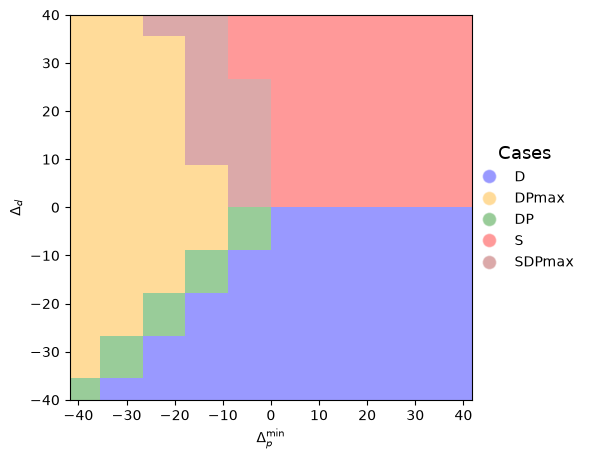

In [12]:
N_value = 1000

small_dim = 10 #100 is max
Delta_ds_min, Delta_ds_max = -40, 40
Delta_p_mins_min, Delta_p_mins_max = -40, 40
Delta_ds = np.linspace(Delta_ds_min, Delta_ds_max, small_dim)
Delta_p_mins = np.linspace(Delta_p_mins_min, Delta_p_mins_max, small_dim)

alpha = 0.4

fig, (ax, ax_legend) = plt.subplots(1, 2, gridspec_kw={'width_ratios': [20, 1]}, figsize=(6,5))

N_ds_all = []
N_ps_all = []
N_ss_all = []
SCs_all = []
cases_all = []
Delta_ds_all = []
Delta_p_mins_all = []

for Delta_d, Delta_p_min in tqdm(itertools.product(Delta_ds, Delta_p_mins), ncols=80, total=small_dim**2):
    N_ds, N_ps, N_ss, SCs, cases =\
        solution_phi_fixed(N = N_value,
                           s = s_value,
                           delta = delta_value,
                           phi = phi_value,
                           f = f_value,
                           E = E_value,
                           M = M_value,
                           Delta_d = Delta_d,
                           #F = stats.uniform(scale=Delta_p_max_minus_min_value, loc=Delta_p_min),
                           F = stats.triang(c = 0.7, scale = Delta_p_max_minus_min_value, loc = Delta_p_min),
                          )

    
    N_ds_all += N_ds
    N_ps_all += N_ps
    N_ss_all += N_ss
    SCs_all += SCs
    cases_all += cases
    Delta_ds_all += [Delta_d for k in range(len(N_ds))]
    Delta_p_mins_all += [Delta_p_min for k in range(len(N_ds))]


N_ds_all = np.array(N_ds_all)
N_ps_all = np.array(N_ps_all)
N_ss_all = np.array(N_ss_all)
SCs_all = np.array(SCs_all)
cases_all = np.array(cases_all)
Delta_ds_all = np.array(Delta_ds_all)
Delta_p_mins_all = np.array(Delta_p_mins_all)
colors_all = case_to_color_transform(cases_all)

dx = Delta_p_mins[1] - Delta_p_mins[0]
dy = Delta_ds[1] - Delta_ds[0]
squares = [plt.Rectangle((x-dx/2, y-dy/2), dx, dy, color=color, alpha=alpha, linewidth=0) for x, y, color in zip(Delta_p_mins_all, Delta_ds_all, colors_all)]
ax.add_collection(mpl.collections.PatchCollection(squares, match_original=True))

ax.set_xlabel(r"$\Delta_p^{\text{min}}$")
ax.set_ylabel(r"$\Delta_d$")

ax.axis("equal")
ax.set_xlim(Delta_p_mins_min, Delta_p_mins_max)
ax.set_ylim(Delta_ds_min, Delta_ds_max)

this_color_legend = {case: color for case, color in zip(color_legend.keys(), color_legend.values()) if case in cases_all}

ax_legend.axis('off')
legend_handles = [plt.Line2D([0], [0], marker='o', color='w', label=case, markerfacecolor=color, markersize=10, alpha=alpha) for case, color in this_color_legend.items()]
ax_legend.legend(handles=legend_handles,
                 loc="center",
                 title='Cases',
                 title_fontsize='13',
                 fontsize='10',
                 frameon=False,
                )

In [13]:
#fig.savefig("outputs/equilibrium_phase_diagram_trig_dist_phi_fixed_N1000000.png")

100%|██████████████████████████████████████| 1000/1000 [00:05<00:00, 194.49it/s]


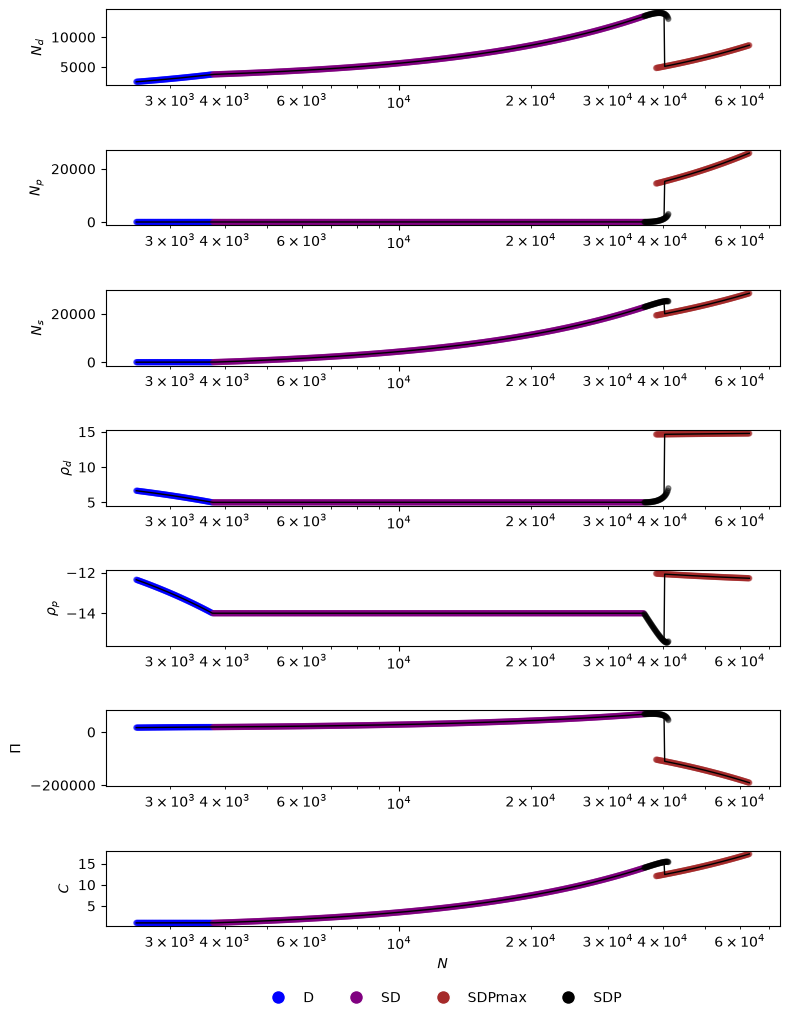

In [14]:
small_dim = 1000
# Ns = np.linspace(np.log(1) / np.log(10), np.log(10000000) / np.log(10), small_dim)
Ns = np.linspace(3.4, 4.8, small_dim)
Ns = 10**(Ns)

Delta_d = -10
Delta_p_min = 10
Delta_p_max_minus_min = 15
phi_value = 0.3
f_value = 1
E_value = 1
alpha_value = 2
beta_value = 1
gamma_value = 4
delta_value = beta_value * gamma_value / (beta_value + gamma_value)
s_value = 2000
M_value = 3




alpha = alpha
alpha_scatter = 0.4

all_axes_names = ["dump_axe",
                  "ax_N_d",
                  "ax_N_p",
                  "ax_N_s",
                  "ax_filling_rate",
                  "ax_N_d2",
                  "ax_N_p2",
                  "ax_N_s2",
                  "ax_SC",
                  "ax_SC_over_N",
                  "ax_rho_d",
                  "ax_rho_p",
                  "ax_profit",
                  "ax_user_cost",
                  "legend_axe",
                 ]

axes_names_to_remove = ["ax_N_d",
                        "ax_N_p",
                        "ax_N_s",
                        "ax_SC",
                        "ax_SC_over_N",
                        "ax_filling_rate",
                       ]

to_draw_axes_names = [ax for ax in all_axes_names if ax not in axes_names_to_remove]

gridspec_kw={'height_ratios': [1 for ax in to_draw_axes_names]}
gridspec_kw["height_ratios"][-1] /=5 

fig, axes_list = plt.subplots(len(to_draw_axes_names), 1, tight_layout=True, figsize=(8, 1.3 * len(to_draw_axes_names)), gridspec_kw=gridspec_kw)

axes_names_translation_dict = dict()
axes_dict = dict()
for axe_name in all_axes_names:
    if axe_name in to_draw_axes_names:
        axes_names_translation_dict[axe_name] = axe_name
    else:
        axes_names_translation_dict[axe_name] = "dump_axe"

for k in range(len(to_draw_axes_names)):
    axes_dict[to_draw_axes_names[k]] = axes_list[k]




axes_dict[axes_names_translation_dict["ax_N_d"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_N_p"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_N_s"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_N_d2"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_N_p2"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_N_s2"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_SC"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_SC_over_N"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_rho_d"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_rho_p"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_profit"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_user_cost"]].set_xscale("log")
axes_dict[axes_names_translation_dict["ax_filling_rate"]].set_xscale("log")


N_ds_selected = []
N_ps_selected = []
N_ss_selected = []
SCs_selected = []
cases_selected = []
Ns_selected = []
rho_ds_selected = []
rho_ps_selected = []
profits_selected = []
user_costs_selected = []

N_ds_all = []
N_ps_all = []
N_ss_all = []
SCs_all = []
cases_all = []
Ns_all = []
rho_ds_all = []
rho_ps_all = []
profits_all = []
user_costs_all = []

for N in tqdm(Ns, ncols=80):

    #F = stats.uniform(scale=Delta_p_max_minus_min_value, loc=Delta_p_min)
    F = stats.triang(c = 0.7, scale = Delta_p_max_minus_min, loc = Delta_p_min)
    
    N_ds_out, N_ps_out, N_ss_out, SCs_out, cases_out =\
        solution_phi_fixed(N = N,
                           s = s_value,
                           delta = delta_value,
                           phi = phi_value,
                           f = f_value,
                           E = E_value,
                           M = M_value,
                           Delta_d = Delta_d,
                           F = F
                          )
    rho_ds_out = []
    rho_ps_out = []
    profits_out = []
    user_costs_out = []
    for k in range(len(N_ds_out)):
        rho_d_out, rho_p_out = toll_values(N_d = N_ds_out[k],
                                           N_p = N_ps_out[k],
                                           N_s = N_ss_out[k],
                                           phi = phi_value,
                                           delta = delta_value,
                                           s = s_value,
                                           f = f_value,
                                           Delta_d = Delta_d,
                                           F = F,
                                          )
        profit_out = N_ds_out[k] * rho_d_out + N_ps_out[k] * rho_p_out
        user_cost = user_cost_s(N_s = N_ss_out[k],
                                phi = phi_value,
                                delta = delta_value,
                                s = s_value,
                                f = f_value,
                               )
        
        rho_ds_out.append(rho_d_out)
        rho_ps_out.append(rho_p_out)
        profits_out.append(profit_out)
        user_costs_out.append(user_cost)

    SC_index_selected = SCs_out.index(min(SCs_out))
    SC_selected = SCs_out[SC_index_selected]
    case_selected = cases_out[SC_index_selected]
    N_d_selected = N_ds_out[SC_index_selected]
    N_p_selected = N_ps_out[SC_index_selected]
    N_s_selected = N_ss_out[SC_index_selected]
    rho_d_selected = rho_ds_out[SC_index_selected]
    rho_p_selected = rho_ps_out[SC_index_selected]
    profit_selected = profits_out[SC_index_selected]
    user_cost_selected = user_costs_out[SC_index_selected]

    N_ds_selected.append(N_d_selected)
    N_ps_selected.append(N_p_selected)
    N_ss_selected.append(N_s_selected)
    SCs_selected.append(SC_selected)
    cases_selected.append(case_selected)
    rho_ds_selected.append(rho_d_selected)
    rho_ps_selected.append(rho_p_selected)
    profits_selected.append(profit_selected)
    user_costs_selected.append(user_cost_selected)
    Ns_selected.append(N)

    N_ds_all += N_ds_out
    N_ps_all += N_ps_out
    N_ss_all += N_ss_out
    SCs_all += SCs_out
    cases_all += cases_out
    rho_ds_all += rho_ds_out
    rho_ps_all += rho_ps_out
    profits_all += profits_out
    user_costs_all += user_costs_out
    Ns_all += [N for k in range(len(N_ds_out))]

N_ds_selected = np.array(N_ds_selected)
N_ps_selected = np.array(N_ps_selected)
N_ss_selected = np.array(N_ss_selected)
SCs_selected = np.array(SCs_selected)
cases_selected = np.array(cases_selected)
Ns_selected = np.array(Ns_selected)
N_ds_all = np.array(N_ds_all)
N_ps_all = np.array(N_ps_all)
N_ss_all = np.array(N_ss_all)
SCs_all = np.array(SCs_all)
cases_all = np.array(cases_all)
Ns_all = np.array(Ns_all)

colors_selected = case_to_color_transform(cases_selected)
colors_all = case_to_color_transform(cases_all)

axes_dict[axes_names_translation_dict["ax_N_d"]].plot(Ns_selected, N_ds_selected / Ns_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_d"]].scatter(Ns_all, N_ds_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
axes_dict[axes_names_translation_dict["ax_N_d"]].plot(Ns_selected, phi_value / (1 + M_value * phi_value) * np.ones_like(Ns_selected), color="black", linestyle="--")
axes_dict[axes_names_translation_dict["ax_N_d2"]].plot(Ns_selected, N_ds_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_d2"]].scatter(Ns_all, N_ds_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_N_p"]].plot(Ns_selected, N_ps_selected / Ns_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_p"]].scatter(Ns_all, N_ps_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
axes_dict[axes_names_translation_dict["ax_N_p"]].plot(Ns_selected, M_value * phi_value / (1 + M_value * phi_value) * np.ones_like(Ns_selected), color="black", linestyle="--")
axes_dict[axes_names_translation_dict["ax_N_p2"]].plot(Ns_selected, N_ps_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_p2"]].scatter(Ns_all, N_ps_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_N_s"]].plot(Ns_selected, N_ss_selected / Ns_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_s"]].scatter(Ns_all, N_ss_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
axes_dict[axes_names_translation_dict["ax_N_s"]].plot(Ns_selected, (1 - phi_value) / (1 + M_value * phi_value) * np.ones_like(Ns_selected), color="black", linestyle="--")
axes_dict[axes_names_translation_dict["ax_N_s2"]].plot(Ns_selected, N_ss_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_s2"]].scatter(Ns_all, N_ss_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_SC"]].plot(Ns_selected, SCs_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_SC"]].scatter(Ns_all, SCs_all, color=colors_all, alpha=alpha_scatter, s=13)
#axes_dict[axes_names_translation_dict["ax_SC"]].scatter(Ns_all, delta_value * N_ds_all * (N_ds_all + N_ps_all), color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_SC_over_N"]].plot(Ns_selected, SCs_selected / Ns_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_SC_over_N"]].scatter(Ns_all, SCs_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_rho_d"]].plot(Ns_selected, rho_ds_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_rho_d"]].scatter(Ns_all, rho_ds_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_rho_p"]].plot(Ns_selected, rho_ps_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_rho_p"]].scatter(Ns_all, rho_ps_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_profit"]].plot(Ns_selected, profits_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_profit"]].scatter(Ns_all, profits_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_user_cost"]].plot(Ns_selected, user_costs_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_user_cost"]].scatter(Ns_all, user_costs_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_filling_rate"]].plot(Ns_selected, np.ones_like(Ns_selected) * M_value, color="red", linestyle="--", linewidth = 1)
axes_dict[axes_names_translation_dict["ax_filling_rate"]].plot(Ns_selected, N_ps_selected / N_ds_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_filling_rate"]].scatter(Ns_all, N_ps_all / N_ds_all, color=colors_all, alpha=alpha_scatter, s=13)


axes_dict[axes_names_translation_dict["ax_N_d"]].set_ylim(bottom=0, top=1)
axes_dict[axes_names_translation_dict["ax_N_p"]].set_ylim(bottom=0, top=1)
axes_dict[axes_names_translation_dict["ax_N_s"]].set_ylim(bottom=0, top=1)
axes_dict[axes_names_translation_dict["ax_filling_rate"]].set_ylim(bottom=0)

#ax_SC_over_N.set_ylim(bottom=0, top=5)

#profit_positive = -(Delta_d + M_value * (F.ppf(M_value *phi_value /(1 + M_value * phi_value)) - f_value - E_value)) / 2 - M_value * E_value
#print(profit_positive)

axes_dict[to_draw_axes_names[-2]].set_xlabel(r"$N$")

axes_dict[axes_names_translation_dict["ax_N_d"]].set_ylabel(r"$\frac{N_d}{N}$")
axes_dict[axes_names_translation_dict["ax_N_p"]].set_ylabel(r"$\frac{N_p}{N}$")
axes_dict[axes_names_translation_dict["ax_N_s"]].set_ylabel(r"$\frac{N_s}{N}$")
axes_dict[axes_names_translation_dict["ax_N_d2"]].set_ylabel(r"$N_d$")
axes_dict[axes_names_translation_dict["ax_N_p2"]].set_ylabel(r"$N_p$")
axes_dict[axes_names_translation_dict["ax_N_s2"]].set_ylabel(r"$N_s$")
axes_dict[axes_names_translation_dict["ax_SC"]].set_ylabel(r"$SC$")
axes_dict[axes_names_translation_dict["ax_SC_over_N"]].set_ylabel(r"$\frac{SC}{N}$")
axes_dict[axes_names_translation_dict["ax_rho_d"]].set_ylabel(r"$\rho_d$")
axes_dict[axes_names_translation_dict["ax_rho_p"]].set_ylabel(r"$\rho_p$")
axes_dict[axes_names_translation_dict["ax_profit"]].set_ylabel(r"$\Pi$")
axes_dict[axes_names_translation_dict["ax_user_cost"]].set_ylabel(r"$C$")
axes_dict[axes_names_translation_dict["ax_filling_rate"]].set_ylabel(r"$m$")


axes_dict[axes_names_translation_dict["dump_axe"]].remove()

legend_axe = axes_dict[axes_names_translation_dict["legend_axe"]]

this_color_legend = {case: color for case, color in zip(color_legend.keys(), color_legend.values()) if case in cases_all}

legend_axe.axis('off')
legend_handles = [plt.Line2D([0], [0], marker='o', color='w', label=case, markerfacecolor=color, markersize=10, alpha=1) for case, color in this_color_legend.items()]
legend_axe.legend(handles=legend_handles,
                  loc="center",
                  #title='Cases',
                  title_fontsize='13',
                  fontsize='10',
                  frameon=False,
                  ncol=len(legend_handles),
                 )


fig.tight_layout()

In [15]:
# fig.savefig("outputs/evolution_of_values_phi_fixed_1.png")

In [16]:
# import warnings
def solution_phi_fixed_computer_solver(N=N_value,
                                       s=s_value,
                                       delta=delta_value,
                                       phi=phi_value,
                                       f=f_value,
                                       E=E_value,
                                       M=M_value,
                                       Delta_d=Delta_d_values,
                                       F=stats.uniform(loc=1, scale = 3)):



    def SC(x):
        N_d = x[0]
        N_p = x[1]
        N_s = N - x[0] - x[1]
        return delta / s * (N_s**2 / (1 - phi) + N_d * (N_d + N_p) / phi)\
        + (N - N_p) * (f+E)\
        + N_d * Delta_d\
        + N * integr.quad(lambda x: x * F.pdf(x), F.ppf(0), F.ppf(N_p / N))[0]
    
    # do not vectorize as it breaks the dimension detection
    
    def grad_SC(x):
        N_d, N_p, N_s = x[0], x[1], N - x[0] - x[1]

        dSC_dN_d = delta / s * (-2 * N_s / (1 - phi) + (2 * N_d + N_p) / phi) + Delta_d
        dSC_dN_p = delta / s * (-2 * N_s / (1 - phi) + N_d / phi) - f - E + F.ppf(N_p / N)
        return np.array([dSC_dN_d, dSC_dN_p])
    

    def hess_SC(x):
        N_d, N_p, N_s = x[0], x[1], N - x[0] - x[1]

        H00 = 2 * delta / s * (1 / (1 - phi) + 1 / phi)
        H01 = delta / s * (2 / (1 - phi) + 1 / phi)
        #with warnings.catch_warnings(record=True) as caught_warnings:
        #    warnings.simplefilter("always", RuntimeWarning)  # Ensure all warnings are caught
        H11 = 2 * delta / ((1 - phi) * s) + 1 / (N * F.pdf(F.ppf(N_p / N)))
        
        #for warning in caught_warnings:
        #    print(f"Caught warning: {warning.message}")
        #    print(f"N_p: {N_p}, F.ppf(N_p / N)): {(F.ppf(N_p / N))}, F.pdf(F.ppf(N_p / N)): {F.pdf(F.ppf(N_p / N))}")

        return np.array([[H00, H01], [H01, H11]])
    

    bounds = opt.Bounds([0, 1e-6], [N, N * M / (M+1) - 1e-6]) # to avoit division by zero in hessian, we add a small value to the bounds of N_p
#    bounds = [(0, N), (0, N * M / (M+1))]

    linear_constraints = opt.LinearConstraint([[1, 0],
                                               [0, 1],
                                               [1, 1],
                                               [M, -1],
                                              ],
                                              [0,
                                               0,
                                               -np.inf,
                                               0,
                                              ],
                                              [np.inf,
                                               np.inf,
                                               N,
                                               np.inf,
                                              ])
    
    result = opt.shgo(func=SC,
                      bounds=bounds,
                      constraints=linear_constraints,
                      n=200,
                      sampling_method='sobol',
                      minimizer_kwargs={'method': 'trust-constr',
                                        'jac': grad_SC,
                                        'hess': hess_SC,
                                        'options': {'disp': False, 'gtol': 1e-6, 'xtol': 1e-6}},
                      )
    
    return result

In [17]:
N_value = 10000
s_value = 2000
alpha_value = 2
beta_value = 1
gamma_value = 4 
delta_value = beta_value * gamma_value / (beta_value + gamma_value)
phi_value = 0.3
f_value = 1
E_value = 1
M_value = 3
Delta_p_max_minus_min_value = 15
Delta_p_min_value = -1.6
Delta_d_value = -6.5

print("this is with gradient descent")

a = solution_phi_fixed_computer_solver(N = N_value,
                                       s = s_value,
                                       delta = delta_value,
                                       phi = phi_value,
                                       f = f_value,
                                       E = E_value,
                                       M = M_value,
                                       Delta_d = Delta_d_value,
                                       F = stats.triang(c=0.7, scale=Delta_p_max_minus_min_value, loc=Delta_p_min_value),
                                      )

print(a)
print()
print("this is our method")

b = solution_phi_fixed(N = N_value,
                       s = s_value,
                       delta = delta_value,
                       phi = phi_value,
                       f = f_value,
                       E = E_value,
                       M = M_value,
                       Delta_d = Delta_d_value,
                       F = stats.triang(c=0.7, scale=Delta_p_max_minus_min_value, loc=Delta_p_min_value),
                      )

print(b)

this is with gradient descent


/var/home/martinbriand/Documents/work/trapeze_bottleneck_local/repo/.venv/lib/python3.13/site-packages/scipy/optimize/_differentiable_functions.py:800: RuntimeWarning: invalid value encountered in dot
  self.f = self.J.dot(self.x)


 message: Optimization terminated successfully.
 success: True
     fun: 33986.89086879888
    funl: [ 3.399e+04]
       x: [ 4.109e+03  9.186e+02]
      xl: [[ 4.109e+03  9.186e+02]]
     nit: 1
    nfev: 139
   nlfev: 7
   nljev: 7
   nlhev: 7

this is our method
([4109.158319448259], [918.6025854642171], [4972.239095087523], [33986.89086879887], ['SDP'])


### trying to find a pseudo real case

In [18]:
# according to le goff these in a sample of drivers:

asc = pd.DataFrame(data=[[0., 0., 0., 0.],
                         [-3.042, 2.103, -2.659, 1.100],
                         [-5.531, 2.554, -1.832, -1.068],
                         [-4.396, 2.507, 0.997, -1.659],
                        ],
                   columns=["A", "B", "C", "D"],
                   index=["sdriver", "cdriver", "cpassenger", "pt"]
                  )

asc = asc.transpose().stack().rename("asc")
asc.index.rename(["class", "mode"], inplace=True)

vtts = pd.DataFrame(data=[[0.280, 0.454, 0.443, 0.208],
                          [0.432, 0.719, 0.290, 0.313],
                          [0.113, 0.620, 0.278, 0.185],
                          [0.237, 0.714, 0.400, 0.293]
                         ])\
    .transpose()\
    .stack()

df = asc.copy().to_frame()
df["vtts"] = vtts.to_numpy()
df["costs"] = -0.132

df.loc["A", "proportion"] = 0.20
df.loc["B", "proportion"] = 0.35
df.loc["C", "proportion"] = 0.12
df.loc["D", "proportion"] = 0.32

df["proportion"] /= df.groupby("class")["proportion"].first().sum()

del asc, vtts

In [19]:
real_total_time = 35 # minutes
df["gc"] = real_total_time * df.vtts + df.asc / df.costs

In [20]:
df

asc   vtts  costs  proportion         gc
class mode                                                  
A     sdriver     0.000  0.280 -0.132    0.202020   9.800000
      cdriver    -3.042  0.432 -0.132    0.202020  38.165455
      cpassenger -5.531  0.113 -0.132    0.202020  45.856515
      pt         -4.396  0.237 -0.132    0.202020  41.598030
B     sdriver     0.000  0.454 -0.132    0.353535  15.890000
      cdriver     2.103  0.719 -0.132    0.353535   9.233182
      cpassenger  2.554  0.620 -0.132    0.353535   2.351515
      pt          2.507  0.714 -0.132    0.353535   5.997576
C     sdriver     0.000  0.443 -0.132    0.121212  15.505000
      cdriver    -2.659  0.290 -0.132    0.121212  30.293939
      cpassenger -1.832  0.278 -0.132    0.121212  23.608788
      pt          0.997  0.400 -0.132    0.121212   6.446970
D     sdriver     0.000  0.208 -0.132    0.323232   7.280000
      cdriver     1.100  0.313 -0.132    0.323232   2.621667
      cpassenger -1.068  0.185 -0.132    0.323232  14.565909
      pt         -1.659  0.293 -0.132    0.323232  22.823182

In [21]:
sdriver_selector = (slice(None), "sdriver")
real_alpha = (df.loc[sdriver_selector, "gc"] * df.loc[sdriver_selector, "proportion"]).sum() / real_total_time * 60 # in €/hour
#real_alpha = real_alpha / 3

# we consider that 35 minutes is the reference time
# Therefore we look at the diff between costs for cdrivers and sdrivers

cdriver_selector = (slice(None), "cdriver")
real_Delta_d = ((df.loc[cdriver_selector, "gc"].droplevel("mode")\
                 - df.loc[sdriver_selector, "gc"].droplevel("mode")\
                ) * df.groupby("class").proportion.first()\
               ).sum()

# we then build the Delta_p_func as the difference between Delta_p and Delta_d values for the reference time of 35 mns

cpassenger_selector = (slice(None), "cpassenger")

gc_p_minus_d = df.loc[cpassenger_selector, "gc"].droplevel("mode")\
               - df.loc[cdriver_selector, "gc"].droplevel("mode")
gc_p_minus_d = gc_p_minus_d.to_frame()
gc_p_minus_d["gc"] += real_Delta_d

gc_p_minus_s = df.loc[cpassenger_selector, "gc"].droplevel("mode")\
               - df.loc[sdriver_selector, "gc"].droplevel("mode")
gc_p_minus_s = gc_p_minus_s.to_frame()

gc_p_minus_avg_s = df.loc[cpassenger_selector, "gc"].droplevel("mode")\
                   - (df.loc[sdriver_selector, "gc"] * df.loc[sdriver_selector, "proportion"]).sum()
gc_p_minus_avg_s = gc_p_minus_avg_s.to_frame()

for gc_p in [gc_p_minus_d, gc_p_minus_s, gc_p_minus_avg_s]:
    gc_p.rename(columns={"gc": "cost_diff"}, inplace=True)
    gc_p["proportion"] = df.groupby("class").proportion.first()
    gc_p.sort_values("cost_diff", inplace=True)
    gc_p["cumulative_proportion"] = gc_p.proportion.cumsum()
    #gc_p.drop(columns="proportion")
del gc_p


real_Delta_p_values = gc_p_minus_d.cost_diff.to_numpy()
real_Delta_p_cumprop = gc_p_minus_d.cumulative_proportion.to_numpy()
# real_Delta_p_values = gc_p_minus_s.cost_diff.to_numpy()
# real_Delta_p_cumprop = gc_p_minus_s.cumulative_proportion.to_numpy()
# real_Delta_p_values = gc_p_minus_avg_s.cost_diff.to_numpy()
# real_Delta_p_cumprop = gc_p_minus_avg_s.cumulative_proportion.to_numpy()

In [22]:
gc_p_minus_d

,cost_diff,proportion,cumulative_proportion
class,,,
B,-3.217818,0.353535,0.353535
C,-3.021302,0.121212,0.474747
A,11.354910,0.202020,0.676768
D,15.608092,0.323232,1.000000


In [23]:
gc_p_minus_s

,cost_diff,proportion,cumulative_proportion
class,,,
B,-13.538485,0.353535,0.353535
D,7.285909,0.323232,0.676768
C,8.103788,0.121212,0.797980
A,36.056515,0.202020,1.000000


In [24]:
gc_p_minus_avg_s

,cost_diff,proportion,cumulative_proportion
class,,,
B,-9.478485,0.353535,0.353535
D,2.735909,0.323232,0.676768
C,11.778788,0.121212,0.797980
A,34.026515,0.202020,1.000000


In [25]:
class MyDistributionFunctionClass():
    def __init__(self, values, cumprops, shift):
        
        if len(values.shape) > 2\
            or values.shape != cumprops.shape\
            or values.shape[0] < 2:
            raise ValueError("Values on cumprops must 1 dim, same shape, at least of lenght 2, and shift between 0 and 1")

        if not np.all(np.diff(values) > 0)\
            or not np.all(np.diff(cumprops) > 0)\
            or cumprops[-1] > 1\
            or cumprops[0] < 0:
            raise ValueError("values and cumpropos must be strictly increasing, with cumprops having values between 0 and 1")


        max_shift_left = -np.diff(np.concat([[0], cumprops])).min()
        max_shift_right = np.diff(np.concat([cumprops, [1]])).min()
        if shift < max_shift_left or max_shift_right < shift:
            raise ValueError("shift is too big in absolute value")

        self.__shift = shift
        self.__values = np.array(values)
        self.__cumprops = np.array(cumprops + self.__shift)

        if self.__cumprops[0] > 0:
            first_value = self.__values[0] - 1# -(self.__cumprops[0] - 0) * (self.__values[1] - self.__values[0]) / (self.__cumprops[1] - self.__cumprops[0])
            self.__values = np.concat([[first_value], self.__values])
            self.__cumprops = np.concat([[0], self.__cumprops])
        if self.__cumprops[-1] < 1:
            last_value = self.__values[-1] + 1 # + (1 - self.cumprops[-1]) * (self.__values[-1] - self.__values[-2]) / (self.__cumprops[-1] - self.__cumprops[-2])
            self.__values = np.concat([self.__values, [last_value]])
            self.__cumprops = np.concat([self.__cumprops, [1]])

        self.__cdf = interp.make_interp_spline(self.__values,
                                               self.__cumprops,
                                               k=1,
                                               bc_type=None,
                                               check_finite=True
                                              )
        self.__pdf = self.__cdf.derivative(nu=1)
        
        self.__ppf = interp.make_interp_spline(self.__cumprops,
                                               self.__values,
                                               k=1,
                                               bc_type=None,
                                               check_finite=True
                                              )
        
    def cdf(self, x):
        if isinstance(x, np.ndarray):
            x2 = x.copy()
            x2[x2 < self.__values[0]] = self.__values[0]
            x2[x2 > self.__values[-1]] = self.__values[-1]
        else:
            if x < self.__values[0]:
                x2 = self.__values[0]
            elif x > self.__values[-1]:
                x2 = self.__values[-1]
            else:
                x2 = x
        return self.__cdf(x2)
    

    def pdf(self, x):
        if isinstance(x, np.ndarray):
            res = self.__pdf(x)
            res[x < self.__values[0]] = 0
            res[x > self.__values[-1]] = 0

        else:
            if x < self.__values[0]:
                res = 0.
            elif x > self.__values[-1]:
                res = 0.
            else:
                res = self.__pdf(x)
        return res
    
    
    def ppf(self, x, raise_error=False):
        if isinstance(x, np.ndarray):
            if raise_error:
                if (x < 0).any() or (x > 1).any():
                    raise ValueError("Ppf function can only be called with values between 0 and 1")
            else:
                x2 = x.copy()
                x2[x2 < 0] = np.nan
                x2[x2 > 1] = np.nan
                

        else:
            if x < 0 or x > 1:
                if raise_error:
                    raise ValueError("Ppf function can only be called with values between 0 and 1")
                else:
                    return np.nan
            x2 = x
        return self.__ppf(x2)
          

    @property
    def shift(self):
        return self.__shift
    
    @property
    def values(self):
        return self.__values
    
    @property
    def cumprops(self):
        return self.__cumprops

In [26]:
real_F = MyDistributionFunctionClass(real_Delta_p_values,
                                     real_Delta_p_cumprop,
                                     -np.diff(real_Delta_p_cumprop).min())

print(real_F.cumprops)
print(real_F.values)
print(real_F.cdf(real_F.values))
print(real_F.ppf(real_F.cumprops))

[0.         0.23232323 0.35353535 0.55555556 0.87878788 1.        ]
[-4.21781757 -3.21781757 -3.02130242 11.3549097  15.60809152 16.60809152]
[0.         0.23232323 0.35353535 0.55555556 0.87878788 1.        ]
[-4.21781757 -3.21781757 -3.02130242 11.3549097  15.60809152 16.60809152]


In [27]:
real_F.ppf(0.5)

array(7.40145137)

In [28]:
# Then we add the beta and gamma values
# This time the values from le goff are said (even by the author) to be unexpected.
# It was not what the study was speciffically dedicated to measure, so we fall back to more classical small 82

# we have
real_beta = real_alpha * 3.90 / 6.40 #(or 0.72) 
real_gamma = real_alpha * 15.21 / 6.40 #(or 1.9)

# Then, for the operation cost, we consider that the free-flow time is 20 minutes travelled at 80km / hour
real_free_flow_time = 20
real_distance = real_free_flow_time / 60 * 80
print(f"distance: {real_distance}")
# which gives a operation cost of about 37 cents/km (robinet 2022)
real_f = 0.37 * real_distance
# real_f = real_f / 3
print(f"f: {real_f}")
# And an externality of 1,30 / 100€ per v.km for local pollution
# 0.36 for 1000km for noise
# 256€ / ton CO2 in France in 2025
# 0.256 kgco2eq / km
real_E = real_distance * (1.3/100 + 0.36 / 1000 + 0.256 * 256 / 1000)
# real_E = real_E / 3

print(f"E: {real_E}")

real_delta = real_beta * real_gamma / (real_beta + real_gamma)
print(f"alpha: {real_alpha}")
print(f"beta: {real_beta}")
print(f"gamma: {real_gamma}")
print(f"delta: {real_delta}")

print(f"Delta_d: {real_Delta_d}")

# We suppose that the congestion goes from 1 minute
# to 1.5 the congestion for a 35 minutes trip
# We also suppose that the road is a three lane highway
# each lane has a capacity of 2000 vehicule an hour
# a third of the capacity is reserved for the system
real_s = 3 * 2000
print(f"s: {real_s}")

real_phi = 1 / 3
print(f"phi: {real_phi}")

real_N = real_s * real_alpha * ((real_total_time - real_free_flow_time) / 60) / real_delta
print(f"N for a road with capacity {real_s} without lane reservation nor carpooling: {real_N}")
real_N_for_one_minute_congestion = real_s * real_alpha * (1 / 60) / real_delta

# And again, we suppose a maximum filling rate of 3 passengers
real_M = 3

distance: 26.666666666666664
f: 9.866666666666665
E: 2.103893333333333
alpha: 20.280000000000005
beta: 12.358125000000001
gamma: 48.19668750000002
delta: 9.83605867346939
Delta_d: 3.6638490970309134
s: 6000
phi: 0.3333333333333333
N for a road with capacity 6000 without lane reservation nor carpooling: 3092.7021696252464


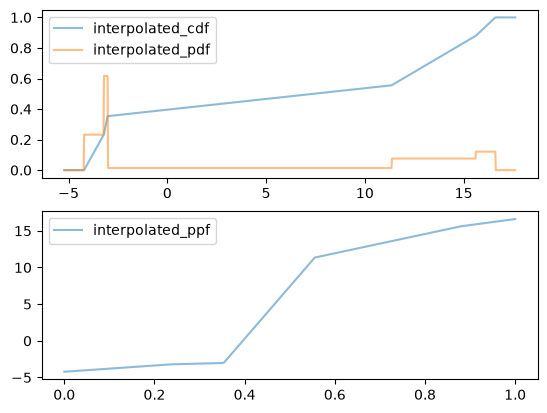

In [29]:
fig, (ax1, ax2) = plt.subplots(2)
x = np.linspace(real_F.values[0]-1, real_F.values[-1] + 1, 1000)
#ax1.plot(real_Delta_p_values, real_Delta_p_cumprop, alpha = 0.5, label="initial")
#ax1.plot(real_F.values, real_F.cumprops, alpha = 0.5, label="final")
ax1.plot(x, real_F.cdf(x), alpha=0.5, label="interpolated_cdf")
ax1.plot(x, real_F.pdf(x), alpha=0.5, label="interpolated_pdf")
ax1.legend()

x = np.linspace(-1, 2, 1000)
#ax2.plot(real_Delta_p_cumprop, real_Delta_p_values, alpha = 0.5, label="initial")
#ax2.plot(real_F.cumprops, real_F.values, alpha = 0.5, label="final")
ax2.plot(x, real_F.ppf(x), alpha=0.5, label="interpolated_ppf")
ax2.legend()

Text(0, 0.5, '$F(x)$')

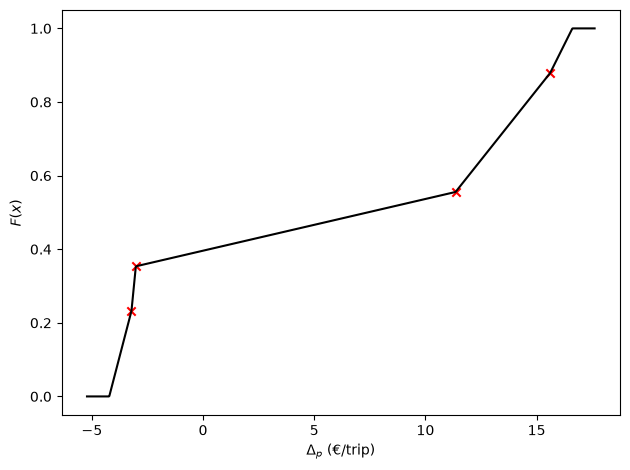

In [30]:
fig, ax = plt.subplots(tight_layout=True)
x = np.linspace(real_F.values[0]-1, real_F.values[-1] + 1, 1000)
ax.plot(x, real_F.cdf(x), color="black")
ax.scatter(real_F.values[1:-1], real_F.cumprops[1:-1], marker="x", color="red")
ax.set_xlabel(r"$\Delta_p$ (€/trip)")
ax.set_ylabel(r"$F(x)$")
#fig.savefig("../outputs/real_Delta_p_dist.png")

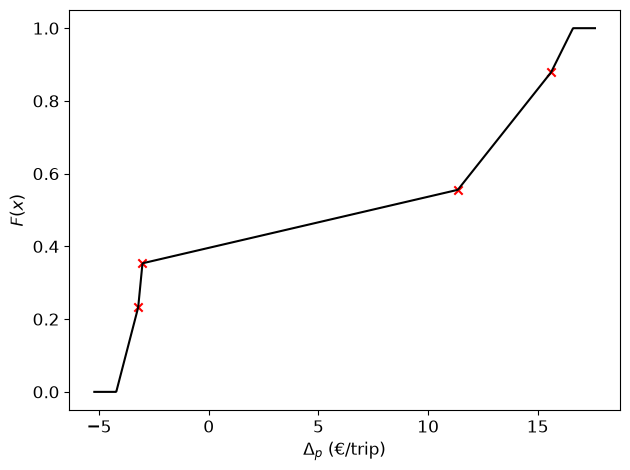

In [31]:
fig, ax = plt.subplots(tight_layout=True)
x = np.linspace(real_F.values[0]-1, real_F.values[-1] + 1, 1000)
ax.plot(x, real_F.cdf(x), color="black")
ax.scatter(real_F.values[1:-1], real_F.cumprops[1:-1], marker="x", color="red")
ax.set_xlabel(r"$\Delta_p$ (€/trip)", fontsize=12)
ax.set_ylabel(r"$F(x)$", fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=12)
fig.savefig("../outputs/real_Delta_p_dist_for_slides.png")

In [32]:
print (real_E / real_distance)
print(0.36 / 1000 + 0.013 + 0.256 * 256 / 1000)

0.07889600000000001
0.078896


In [33]:
real_Delta_p_values = gc_p_minus_d.cost_diff.to_numpy()
real_Delta_p_cumprop = gc_p_minus_d.cumulative_proportion.to_numpy()
# real_Delta_p_values = gc_p_minus_s.cost_diff.to_numpy()
# real_Delta_p_cumprop = gc_p_minus_s.cumulative_proportion.to_numpy()
# real_Delta_p_values = gc_p_minus_avg_s.cost_diff.to_numpy()
# real_Delta_p_cumprop = gc_p_minus_avg_s.cumulative_proportion.to_numpy()

F = real_F = MyDistributionFunctionClass(
    real_Delta_p_values,
    real_Delta_p_cumprop, # do not multiply
    -np.diff(real_Delta_p_cumprop).min(), # Do not multiply
)

shift_p = F.ppf(1/2) * (1-1) # change first 1 by multiplicator
Delta_d_value = real_Delta_d # 2

f_value = real_f # 2

E_value = real_E # 3

alpha_value = real_alpha # 2
beta_value = real_beta # 2
gamma_value = real_gamma # 2

#############
F = real_F = MyDistributionFunctionClass(
    real_Delta_p_values + shift_p,
    real_Delta_p_cumprop, # do not multiply
    -np.diff(real_Delta_p_cumprop).min(), # Do not multiply
)
delta_value = beta_value * gamma_value / (beta_value + gamma_value) # Do not multiply
s_value = real_s # Do not multiply
phi_value = real_phi # Do not multiply
M_value = real_M # Do not multiply
constant_cost_value = alpha_value * real_free_flow_time / 60

  0%|                                                  | 0/1000 [00:00<?, ?it/s]/tmp/ipykernel_33053/793633899.py:17: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  + N * integr.quad(lambda x: x * F.pdf(x), F.ppf(0), F.ppf(N_p / N))[0]
100%|██████████████████████████████████████| 1000/1000 [00:07<00:00, 141.19it/s]


Number of commuters at 15 minutes of extra congestion: 3094.8692282025613
Profit at 15 minutes of extra congestion: -2453.533487187865
rho_d at 15 minutes of extra congestion: -4.119829424768074
rho_p at 15 minutes of extra congestion: -0.12264308809439228
R_{SC} at 15 minutes of extrea congestion: 0.6268435886871045
R_C at 15 minutes of extra congestion: 0.869090577715528
Profit per person at 15 minutes of extra congestion: -0.7927745265711368
Where SC_{\text{1 lane}} crosses SC_{\text{0 lane}}: 1.0000000000000002
Where C_{\text{1 lane}} crosses C_{\text{0 lane}}: 1.0000000000000002
Profit per person limit: -0.21499026719212258


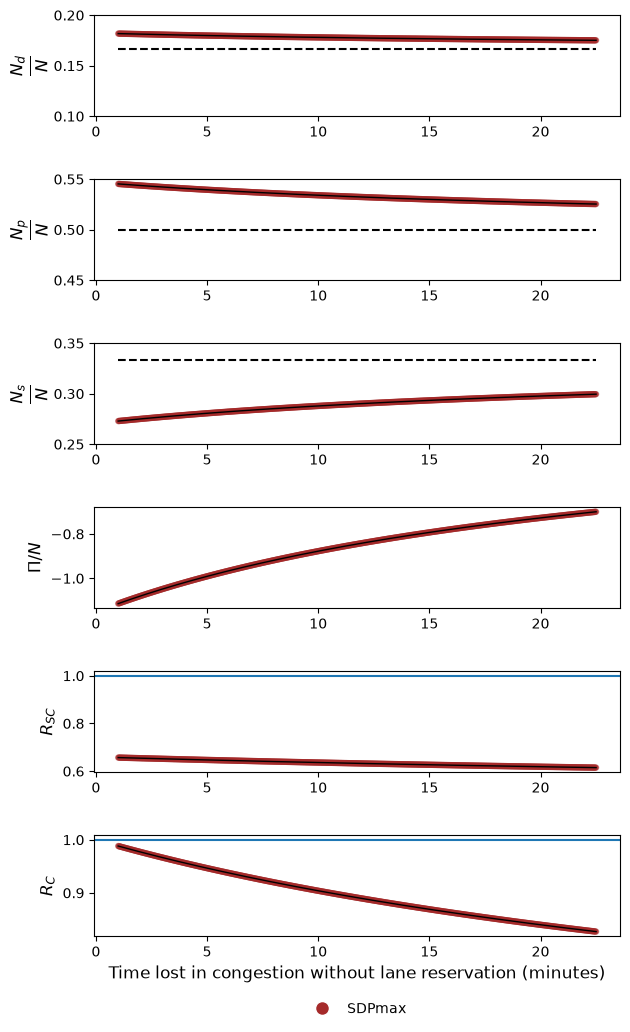

In [34]:
small_dim = 1000
# Ns = np.linspace(np.log(1) / np.log(10), np.log(10000000) / np.log(10), small_dim)
Ns = np.linspace(real_N_for_one_minute_congestion,
                 1.5 * real_N,
                 small_dim)

waiting_times = Ns * real_delta / (real_alpha * real_s)


alpha = alpha
alpha_scatter = 0.4

all_axes_names = ["dump_axe",
                  "ax_N_d",
                  "ax_N_p",
                  "ax_N_s",
                  "ax_filling_rate",
                  "ax_N_d2",
                  "ax_N_p2",
                  "ax_N_s2",
                  "ax_SC",
                  "ax_rho_d",
                  "ax_rho_p",
                  "ax_profit",
                  "ax_SC_over_SC_no_reserved_lane",
                  "ax_user_cost_user_cost_no_reserved_lane",
                  "legend_axe",
                 ]

axes_names_to_remove = ["ax_N_d2",
                        "ax_N_p2",
                        "ax_N_s2",
                        "ax_filling_rate",
                        "ax_rho_d",
                        "ax_rho_p",
                        "ax_SC",
                        #"ax_N_d",
                        #"ax_N_p",
                        #"ax_N_s",
                        #"ax_user_cost_user_cost_no_reserved_lane"
                       ]

to_draw_axes_names = [ax for ax in all_axes_names if ax not in axes_names_to_remove]

gridspec_kw={'height_ratios': [1 for ax in to_draw_axes_names]}
gridspec_kw["height_ratios"][-1] /=5 

fig, axes_list = plt.subplots(len(to_draw_axes_names), 1, tight_layout=True, #figsize=(8, 1.5 * 7 / 6 * len(to_draw_axes_names)), gridspec_kw=gridspec_kw)
figsize=(6.4, 1.5 * len(to_draw_axes_names)), gridspec_kw=gridspec_kw) # remove the *2 in 6.4*2 in pretty printing

axes_names_translation_dict = dict()
axes_dict = dict()
for axe_name in all_axes_names:
    if axe_name in to_draw_axes_names:
        axes_names_translation_dict[axe_name] = axe_name
    else:
        axes_names_translation_dict[axe_name] = "dump_axe"

for k in range(len(to_draw_axes_names)):
    axes_dict[to_draw_axes_names[k]] = axes_list[k]


#axes_dict[axes_names_translation_dict["ax_SC_over_SC_no_reserved_lane"]].set_yscale("log")
#axes_dict[axes_names_translation_dict["ax_user_cost_user_cost_no_reserved_lane"]].set_yscale("log")

N_ds_selected = []
N_ps_selected = []
N_ss_selected = []
SCs_selected = []
cases_selected = []
Ns_selected = []
rho_ds_selected = []
rho_ps_selected = []
profits_selected = []
user_costs_selected = []

N_ds_all = []
N_ps_all = []
N_ss_all = []
SCs_all = []
cases_all = []
Ns_all = []
rho_ds_all = []
rho_ps_all = []
profits_all = []
user_costs_all = []

for N in tqdm(Ns, ncols=80):

    #F = stats.uniform(scale=Delta_p_max_minus_min_value, loc=Delta_p_min)
    #F = stats.triang(c = 0.7, scale = Delta_p_max_minus_min, loc = Delta_p_min)
    
    N_ds_out, N_ps_out, N_ss_out, SCs_out, cases_out =\
        solution_phi_fixed(N = N,
                           s = s_value,
                           delta = delta_value,
                           phi = phi_value,
                           f = f_value,
                           E = E_value,
                           M = M_value,
                           Delta_d = Delta_d_value,
                           F = F
                          )
    rho_ds_out = []
    rho_ps_out = []
    profits_out = []
    user_costs_out = []
    for k in range(len(N_ds_out)):
        rho_d_out, rho_p_out = toll_values(N_d = N_ds_out[k],
                                           N_p = N_ps_out[k],
                                           N_s = N_ss_out[k],
                                           phi = phi_value,
                                           delta = delta_value,
                                           s = s_value,
                                           f = f_value,
                                           Delta_d = Delta_d_value,
                                           F = F,
                                          )
        profit_out = N_ds_out[k] * rho_d_out + N_ps_out[k] * rho_p_out
        user_cost = user_cost_s(N_s = N_ss_out[k],
                                phi = phi_value,
                                delta = delta_value,
                                s = s_value,
                                f = f_value,
                               )
        
        rho_ds_out.append(rho_d_out)
        rho_ps_out.append(rho_p_out)
        profits_out.append(profit_out)
        user_costs_out.append(user_cost + constant_cost_value)
        SCs_out[k] += N * constant_cost_value

    SC_index_selected = SCs_out.index(min(SCs_out))
    SC_selected = SCs_out[SC_index_selected]
    case_selected = cases_out[SC_index_selected]
    N_d_selected = N_ds_out[SC_index_selected]
    N_p_selected = N_ps_out[SC_index_selected]
    N_s_selected = N_ss_out[SC_index_selected]
    rho_d_selected = rho_ds_out[SC_index_selected]
    rho_p_selected = rho_ps_out[SC_index_selected]
    profit_selected = profits_out[SC_index_selected]
    user_cost_selected = user_costs_out[SC_index_selected]

    N_ds_selected.append(N_d_selected)
    N_ps_selected.append(N_p_selected)
    N_ss_selected.append(N_s_selected)
    SCs_selected.append(SC_selected)
    cases_selected.append(case_selected)
    rho_ds_selected.append(rho_d_selected)
    rho_ps_selected.append(rho_p_selected)
    profits_selected.append(profit_selected)
    user_costs_selected.append(user_cost_selected)
    Ns_selected.append(N)

    N_ds_all += N_ds_out
    N_ps_all += N_ps_out
    N_ss_all += N_ss_out
    SCs_all += SCs_out
    cases_all += cases_out
    rho_ds_all += rho_ds_out
    rho_ps_all += rho_ps_out
    profits_all += profits_out
    user_costs_all += user_costs_out
    Ns_all += [N for k in range(len(N_ds_out))]

N_ds_selected = np.array(N_ds_selected)
N_ps_selected = np.array(N_ps_selected)
N_ss_selected = np.array(N_ss_selected)
SCs_selected = np.array(SCs_selected)
cases_selected = np.array(cases_selected)
profits_selected = np.array(profits_selected)
Ns_selected = np.array(Ns_selected)
N_ds_all = np.array(N_ds_all)
N_ps_all = np.array(N_ps_all)
N_ss_all = np.array(N_ss_all)
SCs_all = np.array(SCs_all)
cases_all = np.array(cases_all)
Ns_all = np.array(Ns_all)

waiting_times_selected = Ns_selected * real_delta / (real_alpha * real_s) * 60
waiting_times_all = Ns_all * real_delta / (real_alpha * real_s) * 60

colors_selected = case_to_color_transform(cases_selected)
colors_all = case_to_color_transform(cases_all)

axes_dict[axes_names_translation_dict["ax_N_d"]].plot(waiting_times_selected, N_ds_selected / Ns_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_d"]].scatter(waiting_times_all, N_ds_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
axes_dict[axes_names_translation_dict["ax_N_d"]].plot(waiting_times_selected, phi_value / (1 + M_value * phi_value) * np.ones_like(Ns_selected), color="black", linestyle="--")
axes_dict[axes_names_translation_dict["ax_N_d2"]].plot(waiting_times_selected, N_ds_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_d2"]].scatter(waiting_times_all, N_ds_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_N_p"]].plot(waiting_times_selected, N_ps_selected / Ns_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_p"]].scatter(waiting_times_all, N_ps_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
axes_dict[axes_names_translation_dict["ax_N_p"]].plot(waiting_times_selected, M_value * phi_value / (1 + M_value * phi_value) * np.ones_like(Ns_selected), color="black", linestyle="--")
axes_dict[axes_names_translation_dict["ax_N_p2"]].plot(waiting_times_selected, N_ps_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_p2"]].scatter(waiting_times_all, N_ps_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_N_s"]].plot(waiting_times_selected, N_ss_selected / Ns_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_s"]].scatter(waiting_times_all, N_ss_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
axes_dict[axes_names_translation_dict["ax_N_s"]].plot(waiting_times_selected, (1 - phi_value) / (1 + M_value * phi_value) * np.ones_like(Ns_selected), color="black", linestyle="--")
axes_dict[axes_names_translation_dict["ax_N_s2"]].plot(waiting_times_selected, N_ss_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_N_s2"]].scatter(waiting_times_all, N_ss_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_SC"]].plot(waiting_times_selected, SCs_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_SC"]].scatter(waiting_times_all, SCs_all, color=colors_all, alpha=alpha_scatter, s=13)
#axes_dict[axes_names_translation_dict["ax_SC"]].scatter(waiting_times_all, delta_value * N_ds_all * (N_ds_all + N_ps_all), color=colors_all, alpha=alpha_scatter, s=13)

R_SCs_selected = SCs_selected / (delta_value * Ns_selected**2 / s_value + Ns_selected * (E_value + f_value) + Ns_selected * constant_cost_value)
R_SCs_all = SCs_all / (delta_value * Ns_all**2 / s_value + Ns_all * (E_value + f_value) + Ns_all * constant_cost_value)
axes_dict[axes_names_translation_dict["ax_SC_over_SC_no_reserved_lane"]].plot(waiting_times_selected, R_SCs_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_SC_over_SC_no_reserved_lane"]].scatter(waiting_times_all, R_SCs_all, color=colors_all, alpha=alpha_scatter, s=13)
axes_dict[axes_names_translation_dict["ax_SC_over_SC_no_reserved_lane"]].axhline(1)

axes_dict[axes_names_translation_dict["ax_rho_d"]].plot(waiting_times_selected, rho_ds_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_rho_d"]].scatter(waiting_times_all, rho_ds_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_rho_p"]].plot(waiting_times_selected, rho_ps_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_rho_p"]].scatter(waiting_times_all, rho_ps_all, color=colors_all, alpha=alpha_scatter, s=13)

axes_dict[axes_names_translation_dict["ax_profit"]].plot(waiting_times_selected, profits_selected / Ns_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_profit"]].scatter(waiting_times_all, profits_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)

R_Cs_selected = user_costs_selected / (delta_value * Ns_selected / s_value + f_value + constant_cost_value)
R_Cs_all = user_costs_all / (delta_value * Ns_all / s_value + f_value + constant_cost_value)
axes_dict[axes_names_translation_dict["ax_user_cost_user_cost_no_reserved_lane"]].plot(waiting_times_selected, user_costs_selected / (delta_value * Ns_selected / s_value + f_value + constant_cost_value), alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_user_cost_user_cost_no_reserved_lane"]].scatter(waiting_times_all, user_costs_all / (delta_value * Ns_all / s_value + f_value + constant_cost_value), color=colors_all, alpha=alpha_scatter, s=13)
axes_dict[axes_names_translation_dict["ax_user_cost_user_cost_no_reserved_lane"]].axhline(1)

axes_dict[axes_names_translation_dict["ax_filling_rate"]].plot(waiting_times_selected, np.ones_like(Ns_selected) * M_value, color="red", linestyle="--", linewidth = 1)
axes_dict[axes_names_translation_dict["ax_filling_rate"]].plot(waiting_times_selected, N_ps_selected / N_ds_selected, alpha=1, color="black", linewidth=1)
axes_dict[axes_names_translation_dict["ax_filling_rate"]].scatter(waiting_times_all, N_ps_all / N_ds_all, color=colors_all, alpha=alpha_scatter, s=13)


axes_dict[axes_names_translation_dict["ax_N_d"]].set_ylim(bottom=0.1, top=0.2)
axes_dict[axes_names_translation_dict["ax_N_p"]].set_ylim(bottom=0.45, top=0.55)
axes_dict[axes_names_translation_dict["ax_N_s"]].set_ylim(bottom=0.25, top=0.35)
axes_dict[axes_names_translation_dict["ax_filling_rate"]].set_ylim(bottom=0)
# axes_dict[axes_names_translation_dict["ax_SC_over_delta_N_squared_over_s"]].set_ylim(bottom=0)

#ax_SC_over_N.set_ylim(bottom=0, top=5)


axes_dict[to_draw_axes_names[-2]].set_xlabel("Time lost in congestion without lane reservation (minutes)",#)
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_N_d"]].set_ylabel(r"$\dfrac{N_d}{N}$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_N_p"]].set_ylabel(r"$\dfrac{N_p}{N}$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_N_s"]].set_ylabel(r"$\dfrac{N_s}{N}$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_N_d2"]].set_ylabel(r"$N_d$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_N_p2"]].set_ylabel(r"$N_p$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_N_s2"]].set_ylabel(r"$N_s$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_SC"]].set_ylabel(r"$SC$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_SC_over_SC_no_reserved_lane"]].set_ylabel(r"$R_{SC}$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_rho_d"]].set_ylabel(r"$\rho_d$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_rho_p"]].set_ylabel(r"$\rho_p$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_profit"]].set_ylabel(r"$\Pi / N$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_user_cost_user_cost_no_reserved_lane"]].set_ylabel(r"$R_C$",
    fontsize=12)
axes_dict[axes_names_translation_dict["ax_filling_rate"]].set_ylabel(r"$m$",
    fontsize=12)


axes_dict[axes_names_translation_dict["dump_axe"]].remove()

legend_axe = axes_dict[axes_names_translation_dict["legend_axe"]]

this_color_legend = {case: color for case, color in zip(color_legend.keys(), color_legend.values()) if case in cases_all}

legend_axe.axis('off')
legend_handles = [plt.Line2D([0], [0], marker='o', color='w', label=case, markerfacecolor=color, markersize=10, alpha=1) for case, color in this_color_legend.items()]
legend_axe.legend(handles=legend_handles,
                  loc="center",
                  #title='Cases',
                  title_fontsize='13',
                  fontsize='10',
                  frameon=False,
                  ncol=len(legend_handles),
                 )


#axes_dict[axes_names_translation_dict["ax_SC_over_SC_no_reserved_lane"]].tick_params(axis='both', which='major', labelsize=12)

#formatter = mpl.ticker.ScalarFormatter(useOffset=False, useMathText=False)
#formatter.set_scientific(False)
#axes_dict[axes_names_translation_dict["ax_SC_over_SC_no_reserved_lane"]].yaxis.set_major_formatter(formatter)
#axes_dict[axes_names_translation_dict["ax_SC_over_SC_no_reserved_lane"]].yaxis.set_minor_formatter(formatter)
#axes_dict[axes_names_translation_dict["ax_profit"]].tick_params(axis='both', which='major', labelsize=12)

fig.tight_layout()

idx_15_minutes = np.argmin((waiting_times_selected - 15)**2)
print("Number of commuters at 15 minutes of extra congestion:", Ns_selected[idx_15_minutes])
print("Profit at 15 minutes of extra congestion:", profits_selected[idx_15_minutes])
print("rho_d at 15 minutes of extra congestion:", rho_ds_selected[idx_15_minutes])
print("rho_p at 15 minutes of extra congestion:", rho_ps_selected[idx_15_minutes])
print(r"R_{SC} at 15 minutes of extrea congestion:", R_SCs_selected[idx_15_minutes])
print("R_C at 15 minutes of extra congestion:", R_Cs_selected[idx_15_minutes])
print("Profit per person at 15 minutes of extra congestion:", profits_selected[idx_15_minutes] / Ns_selected[idx_15_minutes])

print(r"Where SC_{\text{1 lane}} crosses SC_{\text{0 lane}}:", waiting_times_selected[np.argmin((R_SCs_selected - 1)**2)])
print(r"Where C_{\text{1 lane}} crosses C_{\text{0 lane}}:", waiting_times_selected[np.argmin((R_Cs_selected - 1)**2)])
#print("Profit per person at the end:", profits_selected[-1] / N)

profit_per_person_limit = ( phi_value / (2 * (1 + M_value * phi_value)) ) * ( -Delta_d_value + M_value * (-F.ppf( (M_value * phi_value) / (1 + M_value * phi_value) ) + f_value - E_value ) ) 

print("Profit per person limit:", profit_per_person_limit)

In [38]:
fig.savefig("../outputs/real_case_output.png", bbox_inches="tight")

# Below is an archive of a dev which was not in the paper : Varying $\varphi$

> Careful, parts of the code below may not work as it was not adapted after code reworks above (not useful for paper)

In [ ]:
def recursive_root_finder_for_case_k_endogenized(f, start_min, start_max, depth, eps = 0.001): # eps is min dist between root
    
    if depth == 0:
        return []

    f_simplified = lambda x: f(x)[0]

    f_value_start_min = f_simplified(start_min)
    f_value_start_max = f_simplified(start_max)

    #print(start_min, start_max, f_value_start_min, f_value_start_max)
    
    if f_value_start_min is None or f_value_start_max is None or f_value_start_min * f_value_start_max > 0:
        middle = (start_max + start_min) / 2
        return recursive_root_finder_for_case_k_endogenized(f, start_min, middle, depth - 1, eps)\
            + recursive_root_finder_for_case_k_endogenized(f, middle + eps, start_max, depth - 1, eps)

    
    root = opt.root_scalar(f_simplified, bracket=[start_min, start_max], method='bisect')

    #print(f_value_start_min, f_value_start_max, root.converged)

    if not root.converged:
        middle = (start_max + start_min) / 2
        return recursive_root_finder_for_case_k_endogenized(f, start_min, middle, depth - 1, eps)\
            + recursive_root_finder_for_case_k_endogenized(f, middle, start_max, depth - 1, eps)
    
    return [(root.root, f(root.root))]\
        + recursive_root_finder_for_case_k_endogenized(f, start_min, root.root - eps, depth - 1, eps)\
        + recursive_root_finder_for_case_k_endogenized(f, root.root + eps, start_max, depth - 1, eps)

In [ ]:
def solution_varying_phi(N=N_value,
                         s=s_value,
                         delta=delta_value,
                         f=f_value,
                         E=E_value,
                         M=M_value,
                         phi_borders=1e-6,
                         Delta_d=Delta_d_values,
                         F=stats.uniform(loc=1, scale = 3),
                         recursive_depth=5
                        ):



    def SC(N_d, N_p, N_s, phi):
        return delta / s * (N_s**2 / (1 - phi) + N_d * (N_d + N_p) / phi)\
        + (N - N_p) * (f+E)\
        + N_d * Delta_d\
        + N * integr.quad(lambda x: x * F.pdf(x), F.ppf(0), F.ppf(N_p / N))[0]

    def partial_hessian_determinant(N_d, N_p, phi):

        N_s = N - N_p - N_d

        H00 = 2 * delta / s * (1 / (1 - phi) + 1 / phi)
        H01 = delta / s * (2 / (1 - phi) + 1 / phi)
        H11 = 2 * delta / ((1 - phi) * s) + 1 / (N * max(F.pdf(F.ppf(N_p / N)), 1e-6))
        #H02 = delta / s * (2 * N_s / (1 - phi) **2 + (2 * N_d + N_p) / phi**2)
        #H12 = delta / s * (2 * N_s / (1 - phi) **2 + N_d / phi**2)
        #H22 = 2 * delta / s * (N_s **2 / (1 - phi) **3 + N_d * (N_d + N_p) / phi**3)

        #hess = np.array([[H00, H01, H02], [H01, H11, H12], [H02, H12, H22]])
        #return np.linalg.det(hess)
        return H00 * H11 - H01**2

    N_ds = []
    N_ps = []
    N_ss = []
    phis = []
    is_phi_indifferents = []
    SCs = []
    cases = []

    # check case a

    case_a_accepted = False

    phi = 1 - phi_borders

    if 2 * delta * N / (phi * s) + Delta_d < 0 and \
    delta * N / (phi * s) + f + E + Delta_d < F.ppf(0):
        case_a_accepted = True
        N_d = N
        N_p = 0
        N_s = 0

    if case_a_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s, phi))
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("a")
        # add the payments


     # check case b

    phi = 1 - phi_borders

    N_d = N / (M+1)
    N_p = M*N / (M + 1)
    N_s = 0
    if 2 * delta * N / (phi * s) + Delta_d  + M * F.ppf(N_p / N) < M * (f + E) and \
    delta * N / (phi * s) + f + E + Delta_d > F.ppf(N_p / N):
        case_b_accepted = True
    else:
        case_b_accepted = False

    if case_b_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s, phi))
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("b")
        # add the payments

    # check case c

    phi = 1 - phi_borders

    case_c_accepted = False
    if F.ppf(0) <= delta * N / (phi * s) + f + E + Delta_d <= F.ppf(M / (M+1)):
        N_p = N * F.cdf(delta * N / (phi * s) + Delta_d + f + E)
        N_d = N - N_p
        N_s = 0

        if delta * N / (phi * s) + delta * N_d / (phi * s) + Delta_d < 0:    
            case_c_accepted = True
    

    if case_c_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s, phi))
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("c")
        # add the payments


    # check case defgh

    phi = phi_borders

    case_defgh_accepted = False
    if Delta_d > 2 * delta * N / ((1 - phi) * s) and \
    Delta_d + M * F.ppf(0) > M * (f + E) + 2 * delta * N * (M + 1) / ((1 - phi) * s):
        case_defgh_accepted = True
        N_d = 0
        N_p = 0
        N_s = N

    if case_defgh_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s, phi))
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("defgh")
        # add the payments

    # check case i

    case_i_accepted = False

    if Delta_d == 0.:
        is_phi_indifferent = True
        phi = 0.5
    if Delta_d > 0:
        is_phi_indifferent = False
        phi = phi_borders
    elif Delta_d < 0:
        is_phi_indifferent = False
        phi = 1 - phi_borders

    if -2 * delta * N / (s * phi) <= Delta_d <= 2 * delta * N / (s * (1 - phi)) and \
    2 * (F.ppf(0) - f - E) - Delta_d * (1 + phi) - 2 * delta * N / s > 0:
        case_i_accepted = True
        N_d = phi * (N - Delta_d / (2 * delta / (s * (1 - phi))))
        N_p = 0
        N_s = N - N_d

    if case_i_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s, phi))
        phis.append(phi)
        is_phi_indifferents.append(is_phi_indifferent)
        cases.append("i")
        # add the payments

    # check case j

    def sign_of_dSC_dphi_j(N_d, phi):
        return (N - (M+1) * N_d) / (1 - phi) - N_d * np.sqrt(M+1) / phi

    def to_zero_func_j(N_d, phi):
        return 2 * delta * (M + 1) / s * (-N / (1 - phi) + (1 + M * phi) / (phi * (1 - phi)) * N_d)\
        + Delta_d + M * (F.ppf(M * N_d / N) - f - E)

    case_j_phi_left_accepted = False

    phi = phi_borders

    if M * F.ppf(0)  - 2 * delta * N * (M + 1) / ((1 - phi) * s) <= M * (f + E) - Delta_d <= M * F.ppf(M / (M+1)) + 2 * delta * N / (phi * s):

        potential_N_d = opt.root_scalar(lambda N_d: to_zero_func_j(N_d, phi), bracket=[0, N / (M + 1)], method='bisect')
        if not potential_N_d.converged:
            raise ValueError("Root finding did not converge for case j_left") # should never happen

        N_d = potential_N_d.root
        N_p = M * N_d
        N_s = N - N_d - N_p
        #print(-N / (1 - phi) + (1 + M * phi) / (phi * (1 - phi)) * N_d)
        #print(sign_of_dSC_dphi_j(N_d, phi))

        if sign_of_dSC_dphi_j(N_d, phi) >= 0\
            and delta / s * (-2 * (N - (M + 1) * N_d) / (1 - phi) + N_d * (M + 2) / phi) + Delta_d > 0:

            case_j_phi_left_accepted = True

    if case_j_phi_left_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s, phi))
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("j_phi_left")


    case_j_phi_right_accepted = False

    phi = 1 - phi_borders

    if M * F.ppf(0)  - 2 * delta * N * (M + 1) / ((1 - phi) * s) <= M * (f + E) - Delta_d <= M * F.ppf(M / (M+1)) + 2 * delta * N / (phi * s):

        potential_N_d = opt.root_scalar(lambda N_d: to_zero_func_j(N_d, phi), bracket=[0, N / (M + 1)], method='bisect')
        if not potential_N_d.converged:
            raise ValueError("Root finding did not converge for case j_left") # should never happen

        N_d = potential_N_d.root
        N_p = M * N_d
        N_s = N - N_d - N_p


        if sign_of_dSC_dphi_j(N_d, phi) <= 0\
            and delta / s * (-2 * (N - (M + 1) * N_d) / (1 - phi) + N_d * (M + 2) / phi) + Delta_d > 0:

            case_j_phi_right_accepted = True

    if case_j_phi_right_accepted:
        N_ds.append(N_d)
        N_ps.append(N_p)
        N_ss.append(N_s)
        SCs.append(SC(N_d, N_p, N_s, phi))
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("j_phi_right")


    case_j_phi_interior_accepted = False

    def N_d_of_phi_null_dSC(phi):
        return N*phi / (phi * (M + 1) + (1 - phi) * np.sqrt(M + 1))

    to_zero_j_interior = lambda phi: to_zero_func_j(N_d_of_phi_null_dSC(phi), phi)
    potential_phis = recursive_root_finder(to_zero_j_interior, phi_borders, 1 - phi_borders, recursive_depth, 1e-6)

    # Here we do not check the second order condition on phi.


    SC_candidate_best = None
    for candidate_phi in potential_phis:
        candidate_N_d = N_d_of_phi_null_dSC(candidate_phi)
        candidate_N_p = M * candidate_N_d
        candidate_N_s = N - candidate_N_d - candidate_N_p

        if M * F.ppf(0)  - 2 * delta * N * (M + 1) / ((1 - phi) * s) <= M * (f + E) - Delta_d <= M * F.ppf(M / (M+1)) + 2 * delta * N / (phi * s)\
            and delta / s * (-2 * (N - (M + 1) * candidate_N_d) / (1 - candidate_phi) + candidate_N_d * (M + 2) / candidate_phi) + Delta_d > 0:
            case_j_phi_interior_accepted = True
            SC_candidate = SC(candidate_N_d, candidate_N_p, candidate_N_s, candidate_phi)
            if SC_candidate_best is None or SC_candidate < SC_candidate_best:
                N_d_best = candidate_N_d
                N_p_best = candidate_N_p
                N_s_best = candidate_N_s
                phi_best = candidate_phi
                SC_candidate_best = SC_candidate

    if case_j_phi_interior_accepted:
        N_ds.append(N_d_best)
        N_ps.append(N_p_best)
        N_ss.append(N_s_best)
        SCs.append(SC_candidate_best)
        phis.append(phi_best)
        is_phi_indifferents.append(False)
        cases.append("j_phi_interior")


    # check case k
    def sign_of_dSC_dphi_k(N_d, N_p, phi):
        return (N - N_d - N_p)**2 / (1 - phi)**2 - N_d * (N_d + N_p) / phi **2

    def to_zero_func_k(N_p, phi):
        return -delta * N / s + delta * N_p / ((1 - phi) * s) * (2 - (1 + phi)**2 / (2 * phi))\
            - Delta_d * (1 + phi) / 2 - f - E + F.ppf(N_p / N)

    def N_d_of_N_p_and_phi_k(N_p, phi):
        return N * phi - N_p * (1 + phi) / 2 - Delta_d * (1 - phi) * phi * s / (2 * delta)

    
    case_k_phi_left_accepted = False
    phi = phi_borders
        
    potential_N_ps = recursive_root_finder(lambda N_p: to_zero_func_k(N_p, phi), 0, N * M / (M + 1), recursive_depth, (N * M / (M + 1)) / 1e-6) # with a depth of five, we may still skip some solutions as well as with the precision
    SC_candidate_best = None

    for candidate_N_p in potential_N_ps:
        candidate_N_d = N_d_of_N_p_and_phi_k(candidate_N_p, phi)
        candidate_N_s = N - candidate_N_d - candidate_N_p

        if candidate_N_d >= candidate_N_p / M\
        and candidate_N_s >= 0\
        and partial_hessian_determinant(candidate_N_d, candidate_N_p, phi) >= 0\
        and sign_of_dSC_dphi_k(candidate_N_d, candidate_N_p, phi) >= 0:
            case_k_phi_left_accepted = True
            #print("youhou (left)")
            SC_candidate = SC(candidate_N_d, candidate_N_p, candidate_N_s, phi)
            if SC_candidate_best is None or SC_candidate < SC_candidate_best:
                N_d_best = candidate_N_d
                N_p_best = candidate_N_p
                N_s_best = candidate_N_s
                SC_candidate_best = SC_candidate

    if case_k_phi_left_accepted:
        N_ds.append(N_d_best)
        N_ps.append(N_p_best)
        N_ss.append(N_s_best)
        SCs.append(SC_candidate_best)
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("k_phi_left")


    case_k_phi_right_accepted = False
    phi = 1 - phi_borders
        
    potential_N_ps = recursive_root_finder(lambda N_p: to_zero_func_k(N_p, phi), 0, N * M / (M + 1), recursive_depth, (N * M / (M + 1)) / 1e-6) # with a depth of five, we may still skip some solutions as well as with the precision
    SC_candidate_best = None
    
    for candidate_N_p in potential_N_ps:
        candidate_N_d = N_d_of_N_p_and_phi_k(candidate_N_p, phi)
        candidate_N_s = N - candidate_N_d - candidate_N_p

        if candidate_N_d >= candidate_N_p / M\
        and candidate_N_s >= 0\
        and partial_hessian_determinant(candidate_N_d, candidate_N_p, phi) >= 0\
        and sign_of_dSC_dphi_k(candidate_N_d, candidate_N_p, phi) <= 0:
            case_k_phi_right_accepted = True
            #print("youhou (right)")
            SC_candidate = SC(candidate_N_d, candidate_N_p, candidate_N_s, phi)
            if SC_candidate_best is None or SC_candidate < SC_candidate_best:
                N_d_best = candidate_N_d
                N_p_best = candidate_N_p
                N_s_best = candidate_N_s
                SC_candidate_best = SC_candidate

    if case_k_phi_right_accepted:
        N_ds.append(N_d_best)
        N_ps.append(N_p_best)
        N_ss.append(N_s_best)
        SCs.append(SC_candidate_best)
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("k_phi_right")


    case_k_phi_interior_accepted = False

    def to_zero_func_interior_k(phi):
        potential_N_ps = recursive_root_finder(lambda N_p: to_zero_func_k(N_p, phi), 0, N * M / (M + 1), recursive_depth, (N * M / (M + 1)) / 1e-6)
        SC_candidate_best = None
        #print(potential_N_ps)
        for candidate_N_p in potential_N_ps:
            candidate_N_d = N_d_of_N_p_and_phi_k(candidate_N_p, phi)
            candidate_N_s = N - candidate_N_d - candidate_N_p

            #print (candidate_N_d, candidate_N_p, candidate_N_s)
            #print(candidate_N_d >= candidate_N_p / M)
            #print(candidate_N_s >= 0)

            if candidate_N_d >= candidate_N_p / M\
            and candidate_N_s >= 0:
            #print("youhou (right)")
                SC_candidate = SC(candidate_N_d, candidate_N_p, candidate_N_s, phi)
                if SC_candidate_best is None or SC_candidate < SC_candidate_best:
                    N_d_best = candidate_N_d
                    N_p_best = candidate_N_p
                    SC_candidate_best = SC_candidate

        if SC_candidate_best is None:
            return (None, None, None)

        
        #print(sign_of_dSC_dphi_k(N_d_best, N_p_best, phi), N_d_best, N_p_best, phi)
        return (sign_of_dSC_dphi_k(N_d_best, N_p_best, phi), N_d_best, N_p_best)

    candidate_solutions = recursive_root_finder_for_case_k_endogenized(to_zero_func_interior_k, phi_borders, 1 - phi_borders, recursive_depth, phi_borders)
    #print(candidate_solutions)
    
    SC_candidate_best = None
    for candidate_solution in candidate_solutions:
        candidate_phi = candidate_solution[0]
        candidate_N_d = candidate_solution[1][1]
        candidate_N_p = candidate_solution[1][2]
        candidate_N_s = N - candidate_N_d - candidate_N_p

        if partial_hessian_determinant(candidate_N_d, candidate_N_p, candidate_phi) >= 0:
            case_k_phi_interior_accepted = True
            SC_candidate = SC(candidate_N_d, candidate_N_p, candidate_N_s, candidate_phi)
            if SC_candidate_best is None or SC_candidate < SC_candidate_best:
                N_d_best = candidate_N_d
                N_p_best = candidate_N_p
                N_s_best = candidate_N_s
                SC_candidate_best = SC_candidate

    if case_k_phi_interior_accepted:
        N_ds.append(N_d_best)
        N_ps.append(N_p_best)
        N_ss.append(N_s_best)
        SCs.append(SC_candidate_best)
        phis.append(phi)
        is_phi_indifferents.append(False)
        cases.append("k_phi_interior")

        
        

    if not any([case_a_accepted,
                case_b_accepted,
                case_c_accepted,
                case_defgh_accepted,
                case_i_accepted,
                case_j_phi_left_accepted,
                case_j_phi_right_accepted,
                case_j_phi_interior_accepted,
                case_k_phi_left_accepted,
                case_k_phi_right_accepted,
                case_k_phi_interior_accepted,
               ]):
        raise ValueError("No case is accepted") # this should never happen

    return N_ds, N_ps, N_ss, SCs, phis, is_phi_indifferents, cases
        
    

In [ ]:
N_value = 10000

small_dim = 10 # max is 100
Delta_ds = np.linspace(-20, 20, small_dim)
Delta_p_mins = np.linspace(-20, 20, small_dim)

alpha = alpha

fig, ax = plt.subplots()

N_ds_all, N_ps_all, N_ss_all, SCs_all, phis_all, is_phi_indifferents_all, cases_all, Delta_d_all, Delta_p_min_all = [], [], [], [], [], [], [], [], []

for Delta_d, Delta_p_min in tqdm(itertools.product(Delta_ds, Delta_p_mins), ncols=80, total=small_dim**2):
    N_ds, N_ps, N_ss, SCs, phis, is_phi_indifferents, cases =\
        solution_varying_phi(N = N_value,
                             s = s_value,
                             delta = delta_value,
                             phi_borders=1e-9,
                             f = f_value,
                             E = E_value,
                             M = M_value,
                             Delta_d = Delta_d,
                             #F = stats.uniform(scale=Delta_p_max_minus_min_value, loc=Delta_p_min),
                             F = stats.triang(c = 0.7, scale = Delta_p_max_minus_min_value, loc = Delta_p_min),
                             recursive_depth = 5
                            )

    
    N_ds_all += N_ds
    N_ps_all += N_ps
    N_ss_all += N_ss
    SCs_all += SCs
    phis_all += phis
    is_phi_indifferents_all += is_phi_indifferents
    cases_all += cases
    Delta_d_all += [Delta_d for k in range(len(N_ds))]
    Delta_p_min_all += [Delta_p_min for k in range(len(N_ds))]


N_ds_all = np.array(N_ds_all)
N_ps_all = np.array(N_ps_all)
N_ss_all = np.array(N_ss_all)
SCs_all = np.array(SCs_all)
cases_all = np.array(cases_all)
Delta_d_all = np.array(Delta_d_all)
Delta_p_min_all = np.array(Delta_p_min_all)
colors_all = case_to_color_transform(cases_all)
phis_all = np.array(phis_all)
is_phi_indifferents_all = np.array(is_phi_indifferents_all)

ax.scatter(Delta_p_min_all, Delta_d_all, color=colors_all, alpha=alpha, s=10, linewidth=0)

ax.set_xlabel(r"$\Delta_p^{\text{min}}$")
ax.set_ylabel(r"$\Delta_d$")

In [ ]:
cases_all

In [ ]:
y1 = -M_value * (Delta_p_mins - f_value - E_value) + 2 * delta_value * (M_value + 1) * N_value / s_value * (1 - 1 / np.sqrt(M_value + 1))
y2 = -M_value * (Delta_p_mins + F.ppf(M_value/(M_value+1)) - F.ppf(0) - f_value - E_value) + 2 * delta_value * N_value / s_value * (np.sqrt(M_value + 1) - 1)

y3 = -M_value * (Delta_p_mins - f_value - E_value) + 2 * delta_value * (M_value + 1) * N_value / s_value
y4 = -M_value * (Delta_p_mins + F.ppf(M_value/(M_value+1)) - F.ppf(0) - f_value - E_value) - 2 * delta_value * N_value / s_value

y1[y1 > 20] = np.nan
y1[y1 < -20] = np.nan
y2[y2 > 20] = np.nan
y2[y2 < -20] = np.nan
y3[y3 > 20] = np.nan
y3[y3 < -20] = np.nan
y4[y4 > 20] = np.nan
y4[y4 < -20] = np.nan


In [ ]:
ax.plot(Delta_p_mins, y1)
ax.plot(Delta_p_mins, y2)
ax.plot(Delta_p_mins, y3)
ax.plot(Delta_p_mins, y4)
fig

In [ ]:
df = pd.DataFrame(data = [pd.Series(N_ds_all, name="N_ds_all"),
                          pd.Series(N_ps_all, name="N_ps_all"),
                          pd.Series(N_ss_all, name="N_ss_all"),
                          pd.Series(SCs_all, name="SCs_all"),
                          pd.Series(cases_all, name="cases_all"),
                          pd.Series(Delta_d_all, name="Delta_d_all"),
                          pd.Series(Delta_p_min_all, name="Delta_p_min_all"),
                          pd.Series(colors_all, name="colors_all"),
                          pd.Series(phis_all, name="phis_all"),
                          pd.Series(is_phi_indifferents_all, name="is_phi_indifferents_all"),
                         ],
                  copy=True
                 )
df = df.transpose(copy=True)

In [ ]:
df.to_parquet("outputs/endogeneous_phi_data.parquet")

In [ ]:
def solution_varying_phi_computer_solver(N=N_value,
                                         s=s_value,
                                         delta=delta_value,
                                         f=f_value,
                                         E=E_value,
                                         M=M_value,
                                         Delta_d=Delta_d_values,
                                         F=stats.uniform(loc=1, scale = 3)):



    def SC(x):
        N_d = x[0]
        N_p = x[1]
        N_s = N - x[0] - x[1]
        phi = max(1e-6, min(x[2], 1 - 1e-6))

        sc = delta / s * (N_s**2 / (1 - phi) + N_d * (N_d + N_p) / phi)\
        + (N - N_p) * (f+E)\
        + N_d * Delta_d\
        + N * integr.quad(lambda x: x * F.pdf(x), F.ppf(0), F.ppf(N_p / N))[0]

        #sc = np.float(sc)

        # if not np.isfinite(sc):
        #     raise ValueError("Here it is sc")
        
        return sc
    
    #SC = np.vectorize(SC) # do not vectorize as it breaks the dimension detection
    
    def grad_SC(x):
        N_d, N_p, N_s = x[0], x[1], N - x[0] - x[1]
        phi = max(1e-6, min(x[2], 1 - 1e-6))
        N_p = max(N * 1e-7, min(N_p, N*(1 - 1e-7)))

        dSC_dN_d = delta / s * (-2 * N_s / (1 - phi) + (2 * N_d + N_p) / phi) + Delta_d
        dSC_dN_p = delta / s * (-2 * N_s / (1 - phi) + N_d / phi) - f - E + F.ppf(N_p / N)
        dSC_dphi = delta / s * (N_s **2 / (1 - phi) **2 - N_d * (N_d + N_p) / phi**2)

        grad = np.array([dSC_dN_d, dSC_dN_p, dSC_dphi])

        # if not np.isfinite(grad).all():
        #     #print(delta / s * (-2 * N_s / (1 - phi) + N_d / phi) - f - E + F.ppf(N_p / N))
        #     print(F.ppf(N_p / N))
        #     print(N_p / N)
        #     raise ValueError("Here it is grad")
        
        return grad
    
    #grad_SC = np.vectorize(grad_SC)

    def hess_SC(x):
        N_d, N_p, N_s = x[0], x[1], N - x[0] - x[1]
        phi = max(1e-6, min(x[2], 1 - 1e-6))
        N_p = max(N * 1e-7, min(N_p, N*(1 - 1e-7)))

        H00 = 2 * delta / s * (1 / (1 - phi) + 1 / phi)
        H01 = delta / s * (2 / (1 - phi) + 1 / phi)
        #with warnings.catch_warnings(record=True) as caught_warnings:
        #    warnings.simplefilter("always", RuntimeWarning)  # Ensure all warnings are caught
        H11 = 2 * delta / ((1 - phi) * s) + 1 / (N * max(F.pdf(F.ppf(N_p / N)), 1e-6))
        
        #for warning in caught_warnings:
        #    print(f"Caught warning: {warning.message}")
        #    print(f"N_p: {N_p}, F.ppf(N_p / N)): {(F.ppf(N_p / N))}, F.pdf(F.ppf(N_p / N)): {F.pdf(F.ppf(N_p / N))}")
        H02 = delta / s * (2 * N_s / (1 - phi) **2 + (2 * N_d + N_p) / phi**2)
        H12 = delta / s * (2 * N_s / (1 - phi) **2 + N_d / phi**2)
        H22 = 2 * delta / s * (N_s **2 / (1 - phi) **3 + N_d * (N_d + N_p) / phi**3)

        hess = np.array([[H00, H01, H02], [H01, H11, H12], [H02, H12, H22]])

        # if not np.isfinite(hess).all():
        #     print(N * max(F.pdf(F.ppf(N_p / N)), 1e-6))
        #     print(N_p / N)
        #     raise ValueError("Here it is hess")

        return hess
    
    #hess_SC = np.vectorize(hess_SC)

    bounds = opt.Bounds([0, 1e-6, 1e-6], [N, N * M / (M+1) - 1e-6, 1 - 1e-6]) # to avoit division by zero in hessian, we add a small value to the bounds of N_p
#    bounds = [(0, N), (0, N * M / (M+1))]

    linear_constraints = opt.LinearConstraint([[1, 0, 0],
                                               [0, 1, 0],
                                               [1, 1, 0],
                                               [M, -1, 0],
                                               [0, 0, 1]
                                              ],
                                              [0,
                                               0,
                                               -np.inf,
                                               0,
                                               1e-6,
                                              ],
                                              [np.inf,
                                               np.inf,
                                               N,
                                               np.inf,
                                               1 - 1e-6,
                                              ])
    
    result = opt.shgo(func=SC,
                      bounds=bounds,
                      constraints=linear_constraints,
                      n=200,
                      sampling_method='sobol',
                      minimizer_kwargs={'method': 'trust-constr',
                                        'jac': grad_SC,
                                        'hess': hess_SC,
                                        'options': {'disp': False, 'gtol': 1e-6, 'xtol': 1e-6}},
                      )
    
    return result

In [ ]:
N_value = 10000
s_value = 2000
alpha_value = 2
beta_value = 1
gamma_value = 4 
delta_value = beta_value * gamma_value / (beta_value + gamma_value)
f_value = 1
E_value = 1
M_value = 3
Delta_p_max_minus_min_value = 15
Delta_p_min_value = 5
Delta_d_value = 5
F = stats.triang(c=0.7, scale=Delta_p_max_minus_min_value, loc=Delta_p_min_value)


print("This is a (take only solutions where phi values are compliant with constraints)")
a = solution_varying_phi_computer_solver(N = N_value,
                                         s = s_value,
                                         delta = delta_value,
                                         f = f_value,
                                         E = E_value,
                                         M = M_value,
                                         Delta_d = Delta_d_value,
                                         F = F,
                                        )

print(a)

print()


print("This is b")
b = solution_varying_phi(N = N_value,
                         s = s_value,
                         delta = delta_value,
                         f = f_value,
                         E = E_value,
                         M = M_value,
                         Delta_d = Delta_d_value,
                         F = F,
                         phi_borders = 1e-9,
                         recursive_depth = 5
                        )



print(b)

In [ ]:
small_N = 1e-9
dim = 100
Delta_p_mins = np.linspace(3, -9, dim)

k = 0
for Delta_p_min in Delta_p_mins:
    F = stats.triang(c=0.7, scale=Delta_p_max_minus_min_value, loc=Delta_p_min)
    b = solution_varying_phi(N = small_N,
                             s = s_value,
                             delta = delta_value,
                             f = f_value,
                             E = E_value,
                             M = M_value,
                             Delta_d = 0,
                             F = F,
                             phi_borders = 1e-9,
                             recursive_depth = 5
                            )

    k += 1
    print(k,"/",dim)
    print(Delta_p_min)
    print(b)

    print()
    print()
    print()

In [ ]:
small_dim = 300
# Ns = np.linspace(np.log(1) / np.log(10), np.log(10000000) / np.log(10), small_dim)
Ns = np.linspace(0, 7, small_dim)
Ns = 10**(Ns)

Delta_d = -20
Delta_p_min = -15
Delta_p_max_minus_min = 15

s_value = 2000
alpha_value = 2
beta_value = 1
gamma_value = 4 
delta_value = beta_value * gamma_value / (beta_value + gamma_value)
f_value = 1
E_value = 1
M_value = 3



alpha = alpha
alpha_scatter = 1

fig, (ax_N_d, ax_N_p, ax_N_s, ax_phi, ax_filling_rate, ax_N_d2, ax_N_p2, ax_N_s2, ax_SC, ax_rho_d, ax_rho_p, ax_profit, ax_user_cost) = plt.subplots(13, 1, tight_layout = True, figsize=(10, 30))
ax_N_d.set_xscale("log")
ax_N_p.set_xscale("log")
ax_N_s.set_xscale("log")
ax_phi.set_xscale("log")
ax_N_d2.set_xscale("log")
ax_N_p2.set_xscale("log")
ax_N_s2.set_xscale("log")
ax_SC.set_xscale("log")
ax_rho_d.set_xscale("log")
ax_rho_p.set_xscale("log")
ax_profit.set_xscale("log")
ax_user_cost.set_xscale("log")
ax_filling_rate.set_xscale("log")


N_ds_selected = []
N_ps_selected = []
N_ss_selected = []
phis_selected = []
SCs_selected = []
cases_selected = []
Ns_selected = []
rho_ds_selected = []
rho_ps_selected = []
profits_selected = []
user_costs_selected = []

N_ds_all = []
N_ps_all = []
N_ss_all = []
phis_all = []
SCs_all = []
cases_all = []
Ns_all = []
rho_ds_all = []
rho_ps_all = []
profits_all = []
user_costs_all = []

for N in tqdm(Ns, ncols=80):

    #F = stats.uniform(scale=Delta_p_max_minus_min_value, loc=Delta_p_min)
    F = stats.triang(c = 0.7, scale = Delta_p_max_minus_min, loc = Delta_p_min)
    
    N_ds_out, N_ps_out, N_ss_out, SCs_out, phis_out, is_phi_indifferrents_out, cases_out =\
        solution_varying_phi(N = N,
                             s = s_value,
                             delta = delta_value,
                             f = f_value,
                             E = E_value,
                             M = M_value,
                             Delta_d = Delta_d,
                             F = F,
                             phi_borders = 1e-9,
                             recursive_depth = 5
                            )
    rho_ds_out = []
    rho_ps_out = []
    profits_out = []
    user_costs_out = []
    for k in range(len(N_ds_out)):
        rho_d_out, rho_p_out = toll_values(N_d = N_ds_out[k],
                                           N_p = N_ps_out[k],
                                           N_s = N_ss_out[k],
                                           phi = phis_out[k],
                                           delta = delta_value,
                                           s = s_value,
                                           f = f_value,
                                           Delta_d = Delta_d,
                                           F = F,
                                          )
        
        profit_out = N_ds_out[k] * rho_d_out + N_ps_out[k] * rho_p_out
        user_cost_out = user_cost_s(N_s = N_ss_out[k],
                                     phi = phis_out[k],
                                     delta = delta_value,
                                     s = s_value,
                                     f = f_value,
                                    )

        
        rho_ds_out.append(rho_d_out)
        rho_ps_out.append(rho_p_out)
        profits_out.append(profit_out)
        user_costs_out.append(user_cost_out)

    SC_index_selected = SCs_out.index(min(SCs_out))
    SC_selected = SCs_out[SC_index_selected]
    case_selected = cases_out[SC_index_selected]
    N_d_selected = N_ds_out[SC_index_selected]
    N_p_selected = N_ps_out[SC_index_selected]
    N_s_selected = N_ss_out[SC_index_selected]
    phi_selected = phis_out[SC_index_selected]
    rho_d_selected = rho_ds_out[SC_index_selected]
    rho_p_selected = rho_ps_out[SC_index_selected]
    profit_selected = profits_out[SC_index_selected]
    user_cost_selected = user_costs_out[SC_index_selected]

    N_ds_selected.append(N_d_selected)
    N_ps_selected.append(N_p_selected)
    N_ss_selected.append(N_s_selected)
    phis_selected.append(phi_selected)
    SCs_selected.append(SC_selected)
    cases_selected.append(case_selected)
    rho_ds_selected.append(rho_d_selected)
    rho_ps_selected.append(rho_p_selected)
    profits_selected.append(profit_selected)
    user_costs_selected.append(user_cost_selected)
    Ns_selected.append(N)

    N_ds_all += N_ds_out
    N_ps_all += N_ps_out
    N_ss_all += N_ss_out
    phis_all += phis_out
    SCs_all += SCs_out
    cases_all += cases_out
    rho_ds_all += rho_ds_out
    rho_ps_all += rho_ps_out
    profits_all += profits_out
    user_costs_all += user_costs_out
    Ns_all += [N for k in range(len(N_ds_out))]

N_ds_selected = np.array(N_ds_selected)
N_ps_selected = np.array(N_ps_selected)
N_ss_selected = np.array(N_ss_selected)
phis_selected = np.array(phis_selected)
SCs_selected = np.array(SCs_selected)
cases_selected = np.array(cases_selected)
Ns_selected = np.array(Ns_selected)
N_ds_all = np.array(N_ds_all)
N_ps_all = np.array(N_ps_all)
N_ss_all = np.array(N_ss_all)
phis_all = np.array(phis_all)
SCs_all = np.array(SCs_all)
cases_all = np.array(cases_all)
Ns_all = np.array(Ns_all)

colors_selected = case_to_color_transform(cases_selected)
colors_all = case_to_color_transform(cases_all)

ax_N_d.plot(Ns_selected, N_ds_selected / Ns_selected, alpha=1, color="black", linewidth=1)
ax_N_d.scatter(Ns_all, N_ds_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
ax_N_d2.plot(Ns_selected, N_ds_selected, alpha=1, color="black", linewidth=1)
ax_N_d2.scatter(Ns_all, N_ds_all, color=colors_all, alpha=alpha_scatter, s=13)

ax_N_p.plot(Ns_selected, N_ps_selected / Ns_selected, alpha=1, color="black", linewidth=1)
ax_N_p.scatter(Ns_all, N_ps_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
ax_N_p2.plot(Ns_selected, N_ps_selected, alpha=1, color="black", linewidth=1)
ax_N_p2.scatter(Ns_all, N_ps_all, color=colors_all, alpha=alpha_scatter, s=13)

ax_N_s.plot(Ns_selected, N_ss_selected / Ns_selected, alpha=1, color="black", linewidth=1)
ax_N_s.scatter(Ns_all, N_ss_all / Ns_all, color=colors_all, alpha=alpha_scatter, s=13)
ax_N_s2.plot(Ns_selected, N_ss_selected, alpha=1, color="black", linewidth=1)
ax_N_s2.scatter(Ns_all, N_ss_all, color=colors_all, alpha=alpha_scatter, s=13)

ax_phi.plot(Ns_selected, phis_selected, alpha=1, color="black", linewidth=1)
ax_phi.scatter(Ns_all, phis_all, color=colors_all, alpha=alpha_scatter, s=13)

ax_SC.plot(Ns_selected, SCs_selected, alpha=1, color="black", linewidth=1)
ax_SC.scatter(Ns_all, SCs_all, color=colors_all, alpha=alpha_scatter, s=13)
#ax_SC.scatter(Ns_all, delta_value * N_ds_all * (N_ds_all + N_ps_all), color=colors_all, alpha=alpha_scatter, s=13)

ax_rho_d.plot(Ns_selected, rho_ds_selected, alpha=1, color="black", linewidth=1)
ax_rho_d.scatter(Ns_all, rho_ds_all, color=colors_all, alpha=alpha_scatter, s=13)

ax_rho_p.plot(Ns_selected, rho_ps_selected, alpha=1, color="black", linewidth=1)
ax_rho_p.scatter(Ns_all, rho_ps_all, color=colors_all, alpha=alpha_scatter, s=13)

ax_profit.plot(Ns_selected, profits_selected, alpha=1, color="black", linewidth=1)
ax_profit.scatter(Ns_all, profits_all, color=colors_all, alpha=alpha_scatter, s=13)

ax_user_cost.plot(Ns_selected, user_costs_selected, alpha=1, color="black", linewidth=1)
ax_user_cost.scatter(Ns_all, user_costs_all, color=colors_all, alpha=alpha_scatter, s=13)

ax_filling_rate.plot(Ns_selected, np.ones_like(Ns_selected) * M_value, color="red", linestyle="--", linewidth = 1)
ax_filling_rate.plot(Ns_selected, N_ps_selected / N_ds_selected, alpha=1, color="black", linewidth=1)
ax_filling_rate.scatter(Ns_all, N_ps_all / N_ds_all, color=colors_all, alpha=alpha_scatter, s=13)


ax_N_d.set_ylim(bottom=0, top=1)
ax_N_p.set_ylim(bottom=0, top=1)
ax_N_s.set_ylim(bottom=0, top=1)
ax_phi.set_ylim(bottom=0, top=1)
ax_filling_rate.set_ylim(bottom=0)

ax_SC.set_xlabel(r"$N$")

ax_N_d.set_ylabel(r"$\frac{N_d}{N}$")
ax_N_p.set_ylabel(r"$\frac{N_p}{N}$")
ax_N_s.set_ylabel(r"$\frac{N_s}{N}$")
ax_N_d2.set_ylabel(r"$N_d$")
ax_N_p2.set_ylabel(r"$N_p$")
ax_N_s2.set_ylabel(r"$N_s$")
ax_phi.set_ylabel(r"$\varphi$")
ax_SC.set_ylabel(r"$SC$")
ax_rho_d.set_ylabel(r"$\rho_d$")
ax_rho_p.set_ylabel(r"$\rho_p$")
ax_profit.set_ylabel(r"$\Pi$")
ax_user_cost.set_ylabel(r"$C$")
ax_filling_rate.set_ylabel(r"$m$")

> Note : if $\varphi \in \{0, 1\}$, the values of $\rho_p$ and $\rho_d$ are not uniquely defined, but we still use some valid values that would result in the calculated equilibrium.
> Same if $N_p = 0$, $\rho_p$ is not uniquely defined, but we still use a valid one.